In [1]:
# ---- PATHS: edit this cell only when the notebook or the data moves -------------------------------------------
from pathlib import Path
STUDY = Path('/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study')
CODE  = STUDY / 'scripts'                     # hhs_data.py (loader), hhs_plot.py (styles, plots)
OUT   = STUDY / 'out'
CACHE = OUT / 'cache_schemes'                 # parquet cache, one set per campaign; delete to re-read
FIGS  = STUDY / 'figures' / 'schemes_comparison'
SAVE_FIGS = False                             # True: every figure also written to FIGS as .png
JOBS = 6

# campaign key -> folder, kind (how folder / file names are parsed), arms to load
CAMPAIGNS = {
    'load':         dict(path=OUT / 'remote_v3',                    arms=['R3', 'R4_bsc', 'R6']),
    'load_fb':      dict(path=OUT / 'remote_v3_fb',                 arms=['R4_bsc_fb']),
    'load_fbs':     dict(path=OUT / 'remote_v3_fbs',                arms=['R4_bsc_fbs']),
    'hmiss':        dict(path=OUT / 'local_helperrx' / 'controlled',    kind='helper_miss'),
    'hmiss_fb':     dict(path=OUT / 'local_helperrx_fb' / 'controlled', kind='helper_miss'),
    'psfch_err':    dict(path=OUT / 'psfch_err',                    kind='psfch_err'),
    'psfch_period': dict(path=OUT / 'remote_psfch',                 kind='psfch_period', arms=['R3', 'R6']),
}

# HARQ schemes comparison: R3, R4+C, R4+C+fb, R6

Every path is in the cell above. Loader: `scripts/hhs_data.py`. Plots and styles: `scripts/hhs_plot.py`.
Builder: `scripts/build_schemes_notebook.py`.

## 1. Data: folders, formats, origin
| key | folder | arms loaded | grid | command | run on | commit |
|---|---|---|---|---|---|---|
| `load` | `out/remote_v3` | R3, R4_bsc, R6 (folder also has R1, R1_bsc, R2, R4, R4.1, R4.2, R5) | 3 routes x 2 traffic x 5 loads (0/15/30/45/60 cars) x 10 seeds | `scripts/launch_v3.sh` -> `study.py run --profile v3 --jobs 32 --out out/v3` | ease-rtx, 32 cores; rsync to laptop | `32e29dd` |
| `load_fb` | `out/remote_v3_fb` | R4_bsc_fb | as `load` | `scripts/launch_v3.sh --fb` (profile `v3_fb`) | ease-rtx | `3d66267` |
| `load_fbs` | `out/remote_v3_fbs` | R4_bsc_fbs | as `load` | `scripts/launch_v3.sh --fbs` (profile `v3_fbs`) | ease-rtx | `a54a785` |
| `hmiss` | `out/local_helperrx/controlled` | R4_bsc (data), R6 (data, sci) | 3 routes x periodic x 0 cars x p = 0.1/0.2/0.3/0.5/0.7 x 10 seeds | `helper_rx_campaign/launch.sh` (`campaign.py`: v3 command + `--helperMissProb=p --helperMissMode=data\|sci`) | laptop, debug build | not recorded |
| `hmiss_fb` | `out/local_helperrx_fb/controlled` | R4_bsc (sci), R4_bsc_fb, R4_bsc_fbs (data, sci) | as `hmiss` | `HRX_OUT=out/local_helperrx_fb helper_rx_campaign/launch.sh --set fb\|fbs` | laptop | not recorded |
| `psfch_err` | `out/psfch_err` | R6: miss 0.01-0.3, n2a 0.001-0.05, power 23/10/0 dBm; R3: miss 0.1, n2a 0.01, 23 dBm | 3 routes x 2 traffic x 0 / 60 cars x 10 seeds | `python3 scripts/psfch_err_sweep.py run --jobs N` (v3 command + `NrSpectrumPhy::SlPsfch*`), then `collect` | laptop, NR `local.patch` | not recorded |
| `psfch_period` | `out/remote_psfch` | R3_p2/p4, R6_p2/p4 (folder also has R1_p0, R2, R4.2) | 3 routes x 2 traffic x 0 / 60 cars x 10 seeds | `scripts/launch_v3.sh --psfch --no-smoke --jobs 32` | ease-rtx | `a515e14` |

p = 0 of the helper-drop sweep and the error-free / period-1 reference of the feedback sweeps are the `load*` runs
(same commands; the local build reproduces v3 bit for bit).

**File names.** `{hwy|rbt|rbtE}_ivd30_{periodic1tb|aperiodic1tb}_{none|n15|n30|n45|moderate}[_p{p}_{data|sci}]_s{seed}_{kind}.csv[.gz]`.
`rbt` = roundabout W, `rbtE` = roundabout E, `moderate` = 60 background cars. Feedback sweeps: arm folder
`{arm}_{miss|n2a|snr_p}{value}` or `{arm}_p{period}`.

| file | rows | columns used here |
|---|---|---|
| `_run.csv` | 1 per run | `kpi_start/end` (3 / 52.7 s), `pkts`, `prr_mean`, `prr_min` (no deadline), `cbr_occupied` (pool CBR), `res_used_leader/helper` (subch.-slots), `subch_prb` |
| `_pkt.csv` | packet x member | `seq, t_tx, size, member, rx, delay_ms, dist_m` |
| `_ltx.csv` / `_htx.csv` | leader / helper transmission | `t, rb_len, tx_in_tb, origin` (0 own slot, 1 takeover after helper NACK, 2 fallback, helper silent) |
| `.cmd.json` | command | full ns-3 command line |

`psfch_err` keeps only `_run.csv` and `.log` per run: no packet traces there (no PIR, no time / distance, P5 over
seeds, resources leader / helper only).

In [2]:
import sys, json, importlib, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
sys.path.insert(0, str(CODE))
import hhs_data as H, hhs_plot as P
importlib.reload(H); importlib.reload(P)
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 200, 'display.max_columns', 40)
FIGS.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    if SAVE_FIGS:
        fig.savefig(FIGS / f'{name}.png', bbox_inches='tight', dpi=150)
    plt.show()

rows = []
for k, s in CAMPAIGNS.items():
    c = s['path'] / 'COMMIT'
    rows.append(dict(key=k, folder=str(s['path'].relative_to(STUDY)) if s['path'].is_relative_to(STUDY) else str(s['path']),
                     exists=s['path'].is_dir(), commit=c.read_text()[:7] if c.exists() else '-',
                     runs_on_disk=len(H.campaign_runs(k, {**s, 'path': str(s['path'])}))))
pd.DataFrame(rows)

,key,folder,exists,commit,runs_on_disk
0,load,out/remote_v3,True,32e29dd,900
1,load_fb,out/remote_v3_fb,True,3d66267,300
2,load_fbs,out/remote_v3_fbs,True,a54a785,300
3,hmiss,out/local_helperrx/controlled,True,-,450
4,hmiss_fb,out/local_helperrx_fb/controlled,True,-,750
5,psfch_err,out/psfch_err,True,-,1680
6,psfch_period,out/remote_psfch,True,a515e14,480


## 2. Schemes
| arm | name | leader HARQ | helper | what differs from the row above |
|---|---|---|---|---|
| R1 | blind repetition | blind, no feedback | none | - |
| R1_bsc | R1 + combining | blind | none | receivers soft-combine the blind copies |
| R2 | Option 1 HARQ | NACK-only (shared PSFCH) | none | feedback-driven retransmissions |
| **R3** | **Option 2 HARQ** | ACK/NACK per member | none | per-member feedback, leader retransmits on any NACK |
| R4 | blind helper | blind | Kuo's helper relays blindly in slots the leader hands over | second transmitter, no feedback |
| **R4_bsc (R4+C)** | **blind helper relaying** | blind | as R4 | receivers soft-combine leader + helper copies |
| **R4_bsc_fb (R4+C+fb)** | **+ fallback** | blind | as R4+C | leader listens to the helper's first handed slot; reclaims the next one if the helper is silent |
| R4_bsc_fbs (R4+C+fb+sp) | + spaced reservations | blind | as R4+C+fb | handed slots keep the PSFCH minimum gap (3 + 2 slots), so the leader can always reclaim |
| R4.1 / R4.2 | helper relay on NACK | Option 1 / Option 2 | relays on NACK | no takeover |
| R5 | cooperative, Option 1 | Option 1 | relay on NACK | takeover, Option 1 feedback |
| **R6** | **cooperative HARQ** | Option 2 | relays on NACK | takeover on helper NACK, fallback when the helper is silent, stop on all-ACK |

Plots use R3, R4+C, R4+C+fb, R4+C+fb+sp, R6. Gain tables use R6 against R3, R4+C, R4+C+fb.
R4 arms send no HARQ feedback: PSFCH errors do not reach them.

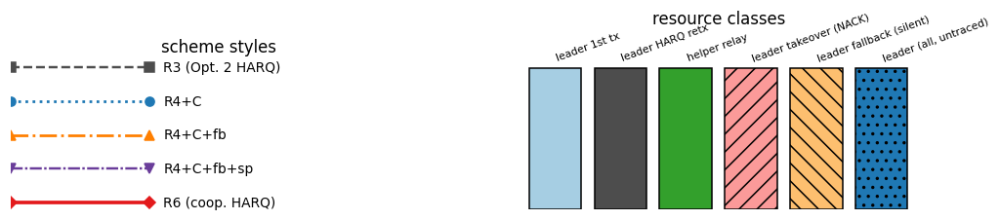

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 1.8))
for i, (a, s) in enumerate(P.STYLE.items()):
    ax[0].plot([0, 1], [-i, -i], color=s['color'], ls=s['ls'], lw=s['lw'], marker=s['marker'])
    ax[0].text(1.1, -i, s['label'], va='center')
for i, (c, s) in enumerate(P.CLASS_STYLE.items()):
    ax[1].bar(i, 1, color=s['color'], hatch=s['hatch'], edgecolor='k')
    ax[1].text(i, 1.05, s['label'], rotation=20, ha='left', fontsize=7)
ax[0].set_xlim(0, 3); [a.axis('off') for a in ax]
ax[0].set_title('scheme styles'); ax[1].set_title('resource classes', pad=25)
plt.show()

## 3. Data objects
`D = H.load(CAMPAIGNS, CACHE)` returns:
- `D['runs']`: one row per run. Keys `campaign, arm, sc, scg (Highway / Roundabouts), tr, nbg, seed, hm_p, hm_mode,
  fb_issue, fb_val`; metrics `prr_group, prr_worst, pir_*, ss_<class>, ss_data_ctrl, kB, ss_kB, cbr`.
- `D['win']`: one row per (run, 2 s window): pairs `n`, delivered `d`, `worst` = worst-member PRR of the window.
- `D['dist']`: one row per (run, 2 s window, 30 m distance bin): `n`, `d`.

In [4]:
D = H.load({k: {**s, 'path': str(s['path'])} for k, s in CAMPAIGNS.items()}, str(CACHE), jobs=JOBS)
R, W, DI = D['runs'], D['win'], D['dist']
print('read errors:', len(D['errors']))
R.pivot_table(index=['campaign', 'arm'], columns='tr', values='seed', aggfunc='size', fill_value=0)

read errors: 0


tr                       aperiodic1tb  periodic1tb
campaign     arm                                  
hmiss        R4_bsc                 0          150
             R6                     0          300
hmiss_fb     R4_bsc                 0          150
             R4_bsc_fb              0          300
             R4_bsc_fbs             0          300
load         R3                   150          150
             R4_bsc               150          150
             R6                   150          150
load_fb      R4_bsc_fb            150          150
load_fbs     R4_bsc_fbs           150          150
psfch_err    R3                   180          180
             R6                   660          660
psfch_period R3                   120          120
             R6                   120          120

## 4. Metrics
Pair = (packet, member). Delivered = received within the PDB (100 ms periodic, 50 ms aperiodic). KPI window 3-52.7 s.

**Reliability**
- **Group PRR**: delivered pairs / pairs, per run; mean over seeds (95 % t-CI).
- **Worst-receiver PRR**: lowest member PRR of the run; mean over seeds.
- **P5 worst-receiver PRR**: 5th percentile, over runs (seeds; both roundabouts pooled in the gain tables), of the
  worst-receiver PRR. Tail of the worst receiver across mobility realisations. (Over 2 s windows it is 0 on the
  roundabouts for every scheme: a member behind a building gets nothing for several seconds.)

**Packet inter-reception (PIR)**: gap between two consecutive delivered packets at one member (reception time =
generation + delay).
- **Group PIR**: mean of all gaps of the run; mean over seeds.
- **Worst-receiver PIR**: largest member mean gap; mean over seeds.
- **P95 worst PIR**: 95th percentile of the gaps of that worst member; mean over seeds.

**Channel resources**: subchannel x slot units (10 PRB x 1 slot) transmitted in the KPI window, PSCCH + PSSCH
(SCI 1-A, SCI 2-A and data share them). PSFCH is left out. Classes (from `_ltx.origin`, `tx_in_tb`, `_htx`):
`L1` leader 1st transmission, `Lrep` leader HARQ retx / blind repetition, `H` helper relay, `T1` leader takeover after
a helper NACK, `T2` leader fallback (helper silent). Normalised by generated data: **subch.-slots per kB** of
application payload generated in the window (`ss_kB`).

Untraced runs (`psfch_err`): PRR = `prr_mean` / `prr_min` of `_run.csv` (no deadline), P5 over seeds, classes leader /
helper only, kB taken from the same command in `load`. Feedback sections 8.1-8.3 compare everything on these
run-level metrics, the references included.

In [5]:
ALL   = ['R3', 'R4_bsc', 'R4_bsc_fb', 'R4_bsc_fbs', 'R6']
SET_A = ['R3', 'R4_bsc', 'R6']
SET_B = ['R3', 'R4_bsc_fb', 'R6']
PRR = ['prr_group', 'prr_worst', 'prr_p5']
PIR = ['pir_mean', 'pir_worst', 'pir_p95']
KEYC = ['campaign', 'arm', 'sc', 'tr', 'nbg', 'seed', 'hm_p', 'hm_mode', 'fb_issue', 'fb_val']

LOAD = R[R.campaign.str.startswith('load')].copy()
LOAD['cbr_lvl'] = LOAD.groupby(['scg', 'tr', 'nbg']).cbr.transform('mean').round(2)
WL = W.merge(LOAD[KEYC], on=KEYC)
DL = DI.merge(LOAD[KEYC], on=KEYC)

def setcols(runs, win, **kv):
    """Copy of runs / win with columns overwritten (used to move reference runs onto a sweep axis)."""
    return runs.assign(**kv), (win.assign(**kv) if win is not None else None)

def runlevel(runs):
    """Run-level PRR (from _run.csv) in place of the packet-level one: for comparisons with untraced runs."""
    return runs.assign(prr_group=runs.prr_run_mean, prr_worst=runs.prr_run_min)

## 5. Reliability vs simulation time and vs distance
Load campaigns, 0 cars (no background) and 60 cars (pool CBR ~0.70). Time: 2 s windows, mean over 10 seeds; rows
group PRR and worst-receiver PRR. Distance: leader-member distance, 30 m bins; rows group PRR (pooled pairs),
worst seed, P5 over (seed x 2 s window).

### 5.1 all schemes

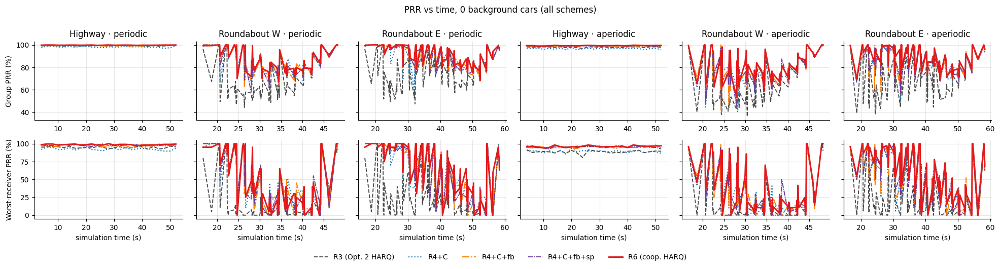

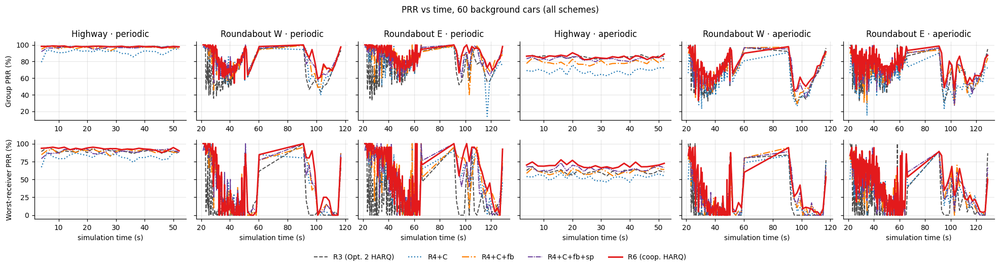

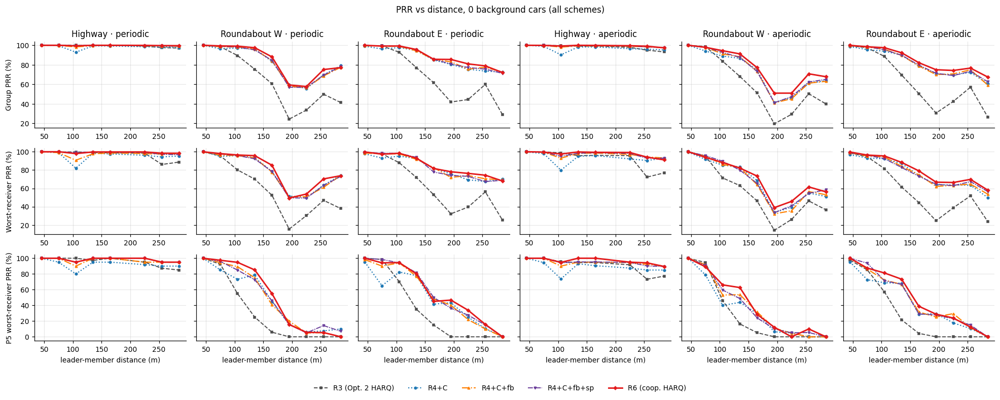

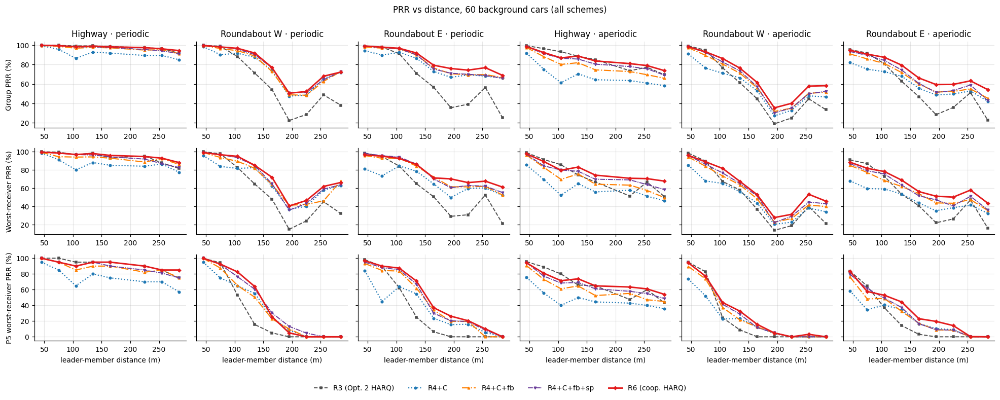

In [6]:
for nbg in (0, 60):
    w = WL[WL.nbg == nbg]
    show(P.plot_series(H.time_series(w, ['arm', 'sc', 'tr']), 't', ['prr_group', 'prr_worst'], ALL,
                       'simulation time (s)', f'PRR vs time, {nbg} background cars (all schemes)'), f'time_all_n{nbg}')
for nbg in (0, 60):
    d = DL[DL.nbg == nbg]
    show(P.plot_series(H.dist_series(d, ['arm', 'sc', 'tr']), 'dbin', PRR, ALL,
                       'leader-member distance (m)', f'PRR vs distance, {nbg} background cars (all schemes)'), f'dist_all_n{nbg}')

### 5.2 R3, R4+C, R6

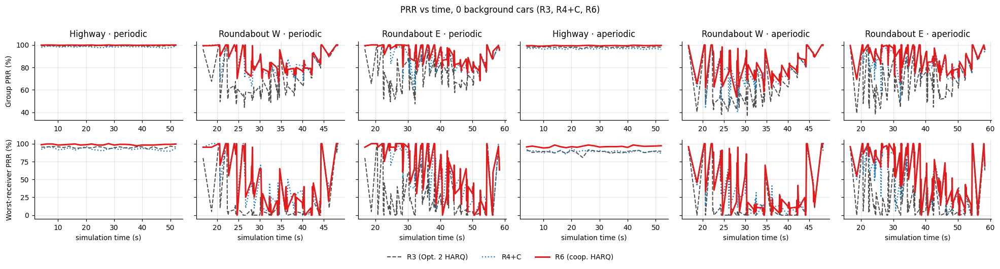

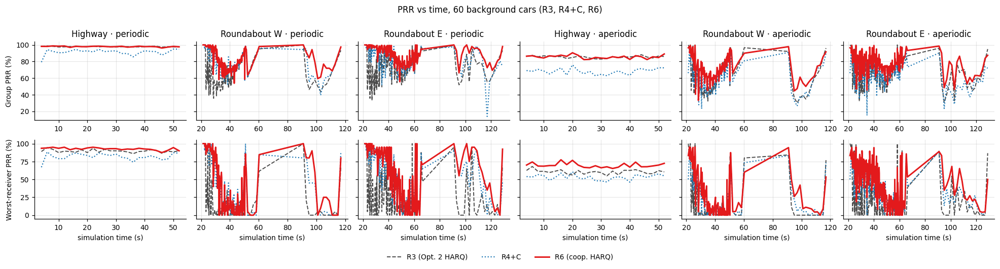

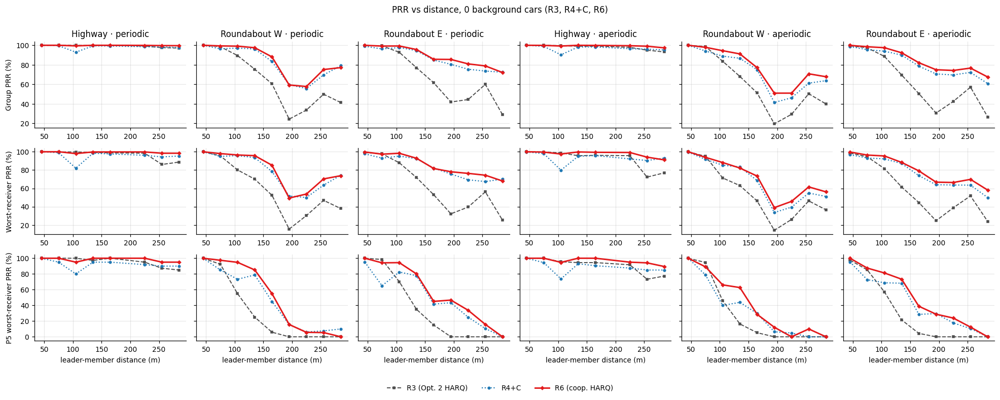

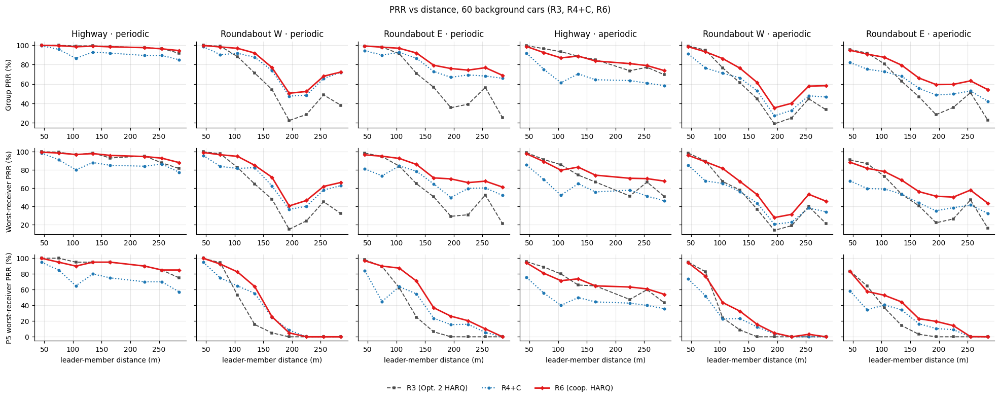

In [7]:
for nbg in (0, 60):
    w = WL[WL.nbg == nbg]
    show(P.plot_series(H.time_series(w, ['arm', 'sc', 'tr']), 't', ['prr_group', 'prr_worst'], SET_A,
                       'simulation time (s)', f'PRR vs time, {nbg} background cars (R3, R4+C, R6)'), f'time_A_n{nbg}')
for nbg in (0, 60):
    d = DL[DL.nbg == nbg]
    show(P.plot_series(H.dist_series(d, ['arm', 'sc', 'tr']), 'dbin', PRR, SET_A,
                       'leader-member distance (m)', f'PRR vs distance, {nbg} background cars (R3, R4+C, R6)'), f'dist_A_n{nbg}')

### 5.3 R3, R4+C+fb, R6

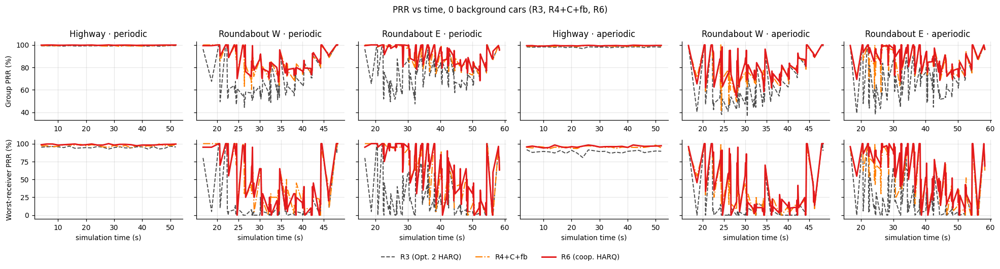

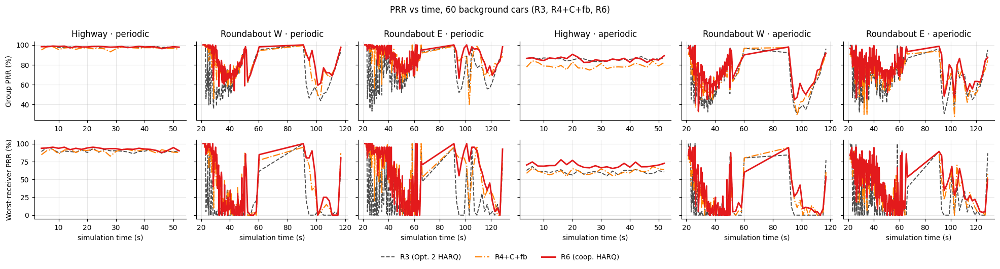

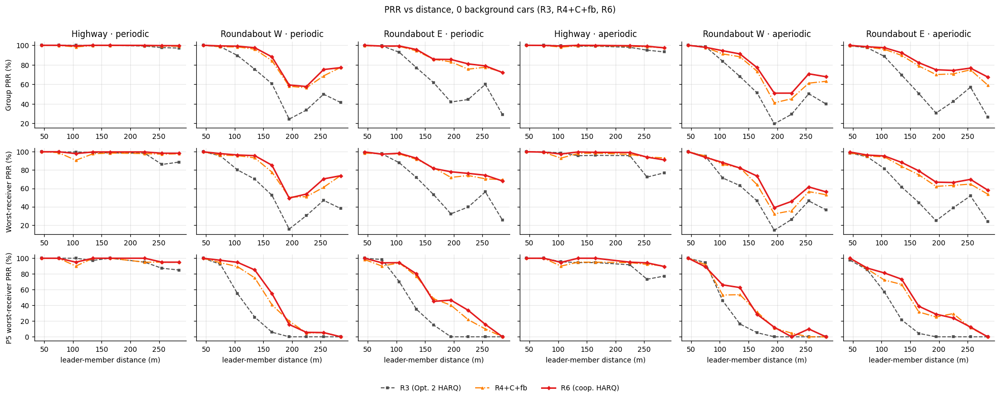

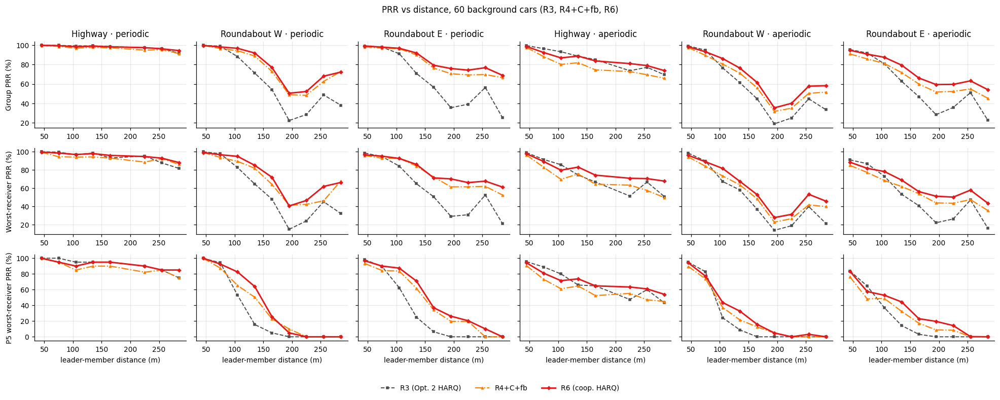

In [8]:
for nbg in (0, 60):
    w = WL[WL.nbg == nbg]
    show(P.plot_series(H.time_series(w, ['arm', 'sc', 'tr']), 't', ['prr_group', 'prr_worst'], SET_B,
                       'simulation time (s)', f'PRR vs time, {nbg} background cars (R3, R4+C+fb, R6)'), f'time_B_n{nbg}')
for nbg in (0, 60):
    d = DL[DL.nbg == nbg]
    show(P.plot_series(H.dist_series(d, ['arm', 'sc', 'tr']), 'dbin', PRR, SET_B,
                       'leader-member distance (m)', f'PRR vs distance, {nbg} background cars (R3, R4+C+fb, R6)'), f'dist_B_n{nbg}')

## 6. Reliability vs background load (pool CBR)
x = pool CBR (`cbr_occupied`) of each arm at 0 / 15 / 30 / 45 / 60 background cars.

In [9]:
S_LOAD = H.summarize(LOAD, WL, ['arm', 'sc', 'tr', 'nbg'])
S_LOAD_G = H.summarize(LOAD, WL, ['arm', 'scg', 'tr', 'cbr_lvl'])
S_LOAD.pivot_table(index=['sc', 'tr', 'nbg'], columns='arm', values='cbr').round(2)

arm                      R3  R4_bsc  R4_bsc_fb  R4_bsc_fbs    R6
sc   tr           nbg                                           
hwy  aperiodic1tb 0    0.01    0.01       0.01        0.01  0.01
                  15   0.24    0.24       0.24        0.24  0.24
                  30   0.43    0.43       0.43        0.43  0.43
                  45   0.59    0.59       0.59        0.59  0.59
                  60   0.70    0.70       0.70        0.70  0.70
     periodic1tb  0    0.00    0.01       0.01        0.01  0.00
                  15   0.24    0.24       0.24        0.24  0.24
                  30   0.42    0.43       0.43        0.43  0.42
                  45   0.59    0.59       0.59        0.59  0.59
                  60   0.70    0.70       0.70        0.70  0.70
rbt  aperiodic1tb 0    0.01    0.01       0.01        0.01  0.01
                  15   0.23    0.23       0.23        0.23  0.23
                  30   0.42    0.42       0.42        0.42  0.42
                  45   0.58    0.58       0.58        0.58  0.58
                  60   0.69    0.69       0.69        0.69  0.69
     periodic1tb  0    0.01    0.01       0.01        0.01  0.01
                  15   0.23    0.23       0.23        0.23  0.23
                  30   0.42    0.42       0.42        0.42  0.42
                  45   0.58    0.58       0.58        0.58  0.58
                  60   0.69    0.69       0.69        0.69  0.69
rbtE aperiodic1tb 0    0.01    0.01       0.01        0.01  0.01
                  15   0.23    0.23       0.23        0.23  0.23
                  30   0.42    0.42       0.42        0.42  0.42
                  45   0.58    0.58       0.58        0.58  0.58
                  60   0.69    0.69       0.69        0.69  0.69
     periodic1tb  0    0.01    0.01       0.01        0.01  0.00
                  15   0.23    0.23       0.23        0.23  0.23
                  30   0.42    0.42       0.42        0.42  0.42
                  45   0.58    0.58       0.58        0.58  0.58
                  60   0.69    0.69       0.69        0.69  0.69

### 6.1 All schemes

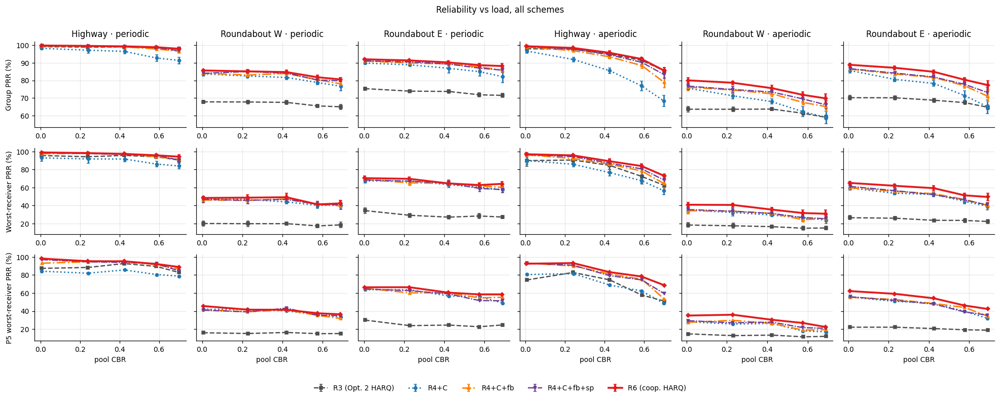

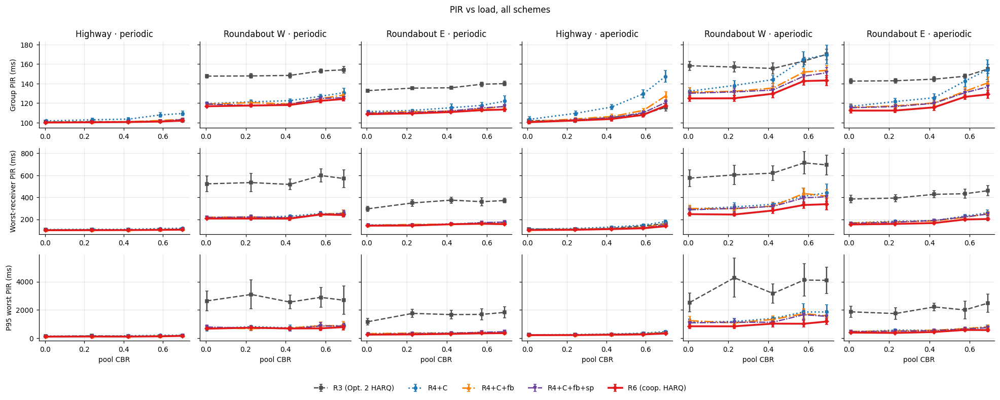

In [10]:
show(P.plot_x(S_LOAD, 'cbr', PRR, ALL, 'pool CBR', 'Reliability vs load, all schemes'), 'cbr_prr_all')
show(P.plot_x(S_LOAD, 'cbr', PIR, ALL, 'pool CBR', 'PIR vs load, all schemes', pct=False), 'cbr_pir_all')

### 6.2 R3, R4+C, R6

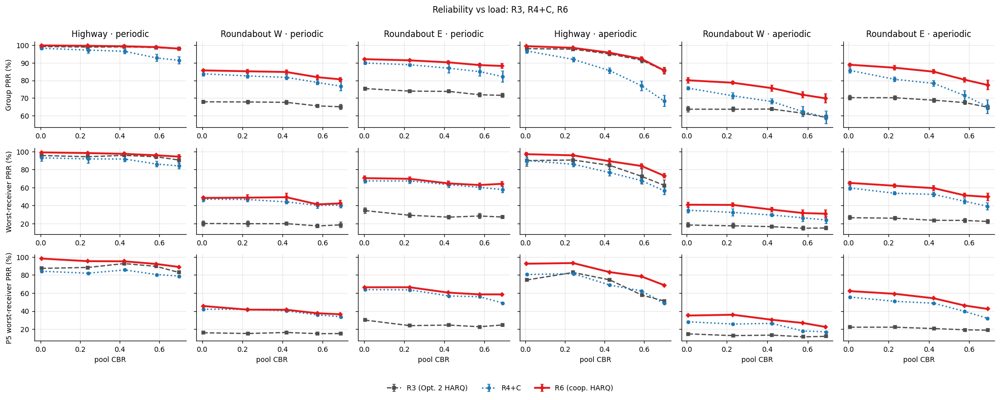

In [11]:
show(P.plot_x(S_LOAD, 'cbr', PRR, SET_A, 'pool CBR', 'Reliability vs load: R3, R4+C, R6'), 'cbr_prr_A')

### 6.3 R3, R4+C+fb, R6

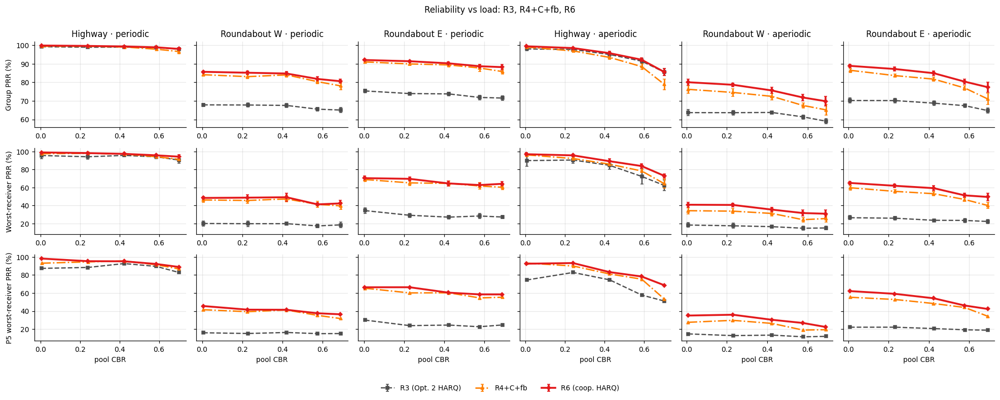

In [12]:
show(P.plot_x(S_LOAD, 'cbr', PRR, SET_B, 'pool CBR', 'Reliability vs load: R3, R4+C+fb, R6'), 'cbr_prr_B')

### 6.4 Resources vs load (data + control, no PSFCH)

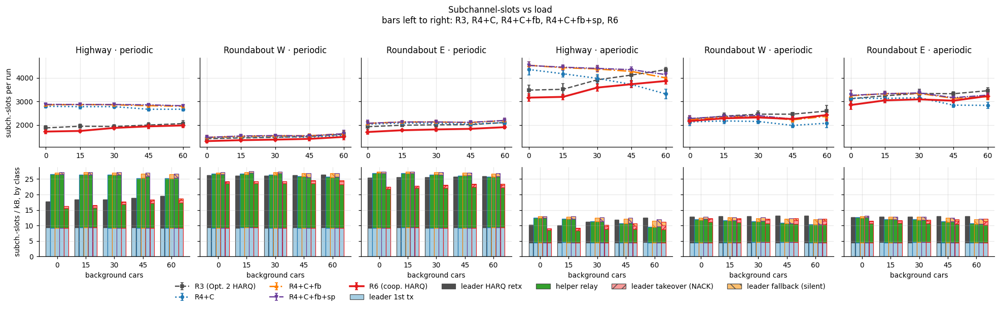

arm                      R3  R4_bsc  R4_bsc_fb  R4_bsc_fbs    R6
sc   tr           nbg                                           
hwy  aperiodic1tb 0    10.2    12.5       13.0        13.0   9.1
                  15   10.1    12.1       12.9        12.9   9.3
                  30   11.2    11.4       12.5        12.6  10.2
                  45   11.8    10.6       12.2        12.4  10.6
                  60   12.4     9.5       11.5        11.9  11.1
     periodic1tb  0    17.8    26.5       27.1        27.3  16.3
                  15   18.4    26.3       27.2        27.2  16.5
                  30   18.3    26.3       27.1        27.2  17.7
                  45   18.9    25.3       26.7        27.1  18.4
                  60   19.5    25.3       26.5        26.7  18.8
rbt  aperiodic1tb 0    12.8    12.0       12.6        12.8  12.2
                  15   12.9    11.6       12.6        12.7  12.2
                  30   13.0    11.3       12.4        12.6  12.2
                  45   13.1    10.8       12.1        12.3  12.3
                  60   13.1    10.4       11.9        12.1  12.2
     periodic1tb  0    26.1    26.8       27.1        27.2  24.2
                  15   26.0    26.7       27.2        27.5  24.3
                  30   26.1    26.4       27.2        27.4  24.3
                  45   26.3    25.9       26.9        26.8  24.6
                  60   26.4    25.8       26.8        26.9  24.7
rbtE aperiodic1tb 0    12.6    12.6       13.0        13.1  11.4
                  15   12.8    12.0       12.8        12.8  11.7
                  30   12.9    12.0       12.7        12.8  11.8
                  45   13.0    11.3       12.4        12.5  12.0
                  60   13.0    10.6       12.0        12.2  12.1
     periodic1tb  0    25.4    26.8       27.3        27.3  22.5
                  15   25.6    26.8       27.4        27.4  22.9
                  30   25.6    26.4       27.2        27.2  23.1
                  45   25.8    26.1       27.0        27.0  23.5
                  60   25.8    25.8       26.8        26.9  23.4

In [13]:
show(P.plot_resources(S_LOAD, 'nbg', ALL, 'background cars', 'Subchannel-slots vs load', xcat=True,
                      xticklabels=['0', '15', '30', '45', '60']), 'cbr_res_all')
S_LOAD.pivot_table(index=['sc', 'tr', 'nbg'], columns='arm', values='ss_kB').round(1)

## 7. Reliability vs helper drop probability
Forced miss of the leader's first copy at the selected helper, probability p (periodic traffic, 0 cars).
`sci`: SCI 2-A lost, helper silent. `data`: SCI 2-A decoded, TB lost, helper NACKs and drops its buffer.
p = 0 from the load campaigns. R3 has no helper: its p = 0 value is repeated on every p.

In [14]:
HM_P = [0.0, 0.1, 0.2, 0.3, 0.5, 0.7]
def hm_frame(mode):
    hm = R[R.campaign.str.startswith('hmiss') & (R.hm_mode == mode)]
    hw = W.merge(hm[KEYC], on=KEYC)
    ref = LOAD[(LOAD.tr == 'periodic1tb') & (LOAD.nbg == 0)]
    rw = WL.merge(ref[KEYC], on=KEYC)
    parts = [(hm, hw)]
    for arm in ['R4_bsc', 'R4_bsc_fb', 'R4_bsc_fbs', 'R6']:
        a = ref[ref.arm == arm]
        parts.append(setcols(a, rw.merge(a[KEYC], on=KEYC), hm_mode=mode, hm_p=0.0))
    r3 = ref[ref.arm == 'R3']
    for p in HM_P:
        parts.append(setcols(r3, rw.merge(r3[KEYC], on=KEYC), hm_mode=mode, hm_p=p))
    return pd.concat([p[0] for p in parts]), pd.concat([p[1] for p in parts])

HM = {m: hm_frame(m) for m in ('sci', 'data')}
S_HM = {m: H.summarize(*HM[m], ['arm', 'sc', 'tr', 'hm_p']) for m in HM}
S_HM_G = {m: H.summarize(*HM[m], ['arm', 'scg', 'tr', 'hm_p']) for m in HM}

### 7.1 Helper SCI drop (helper silent)

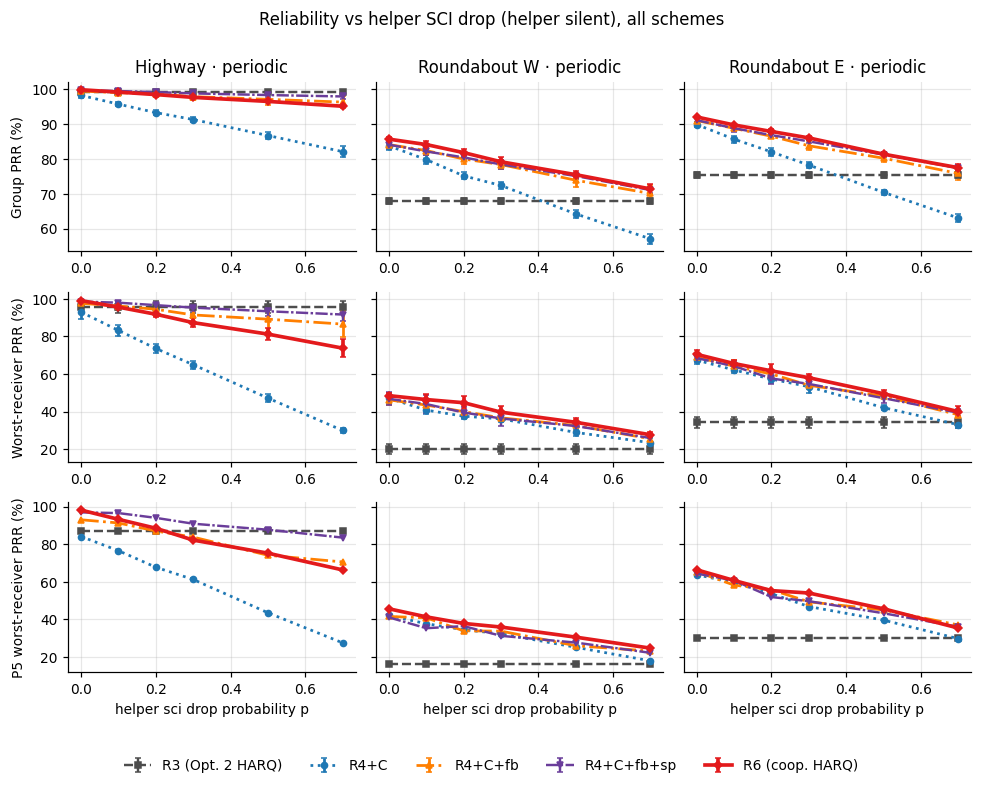

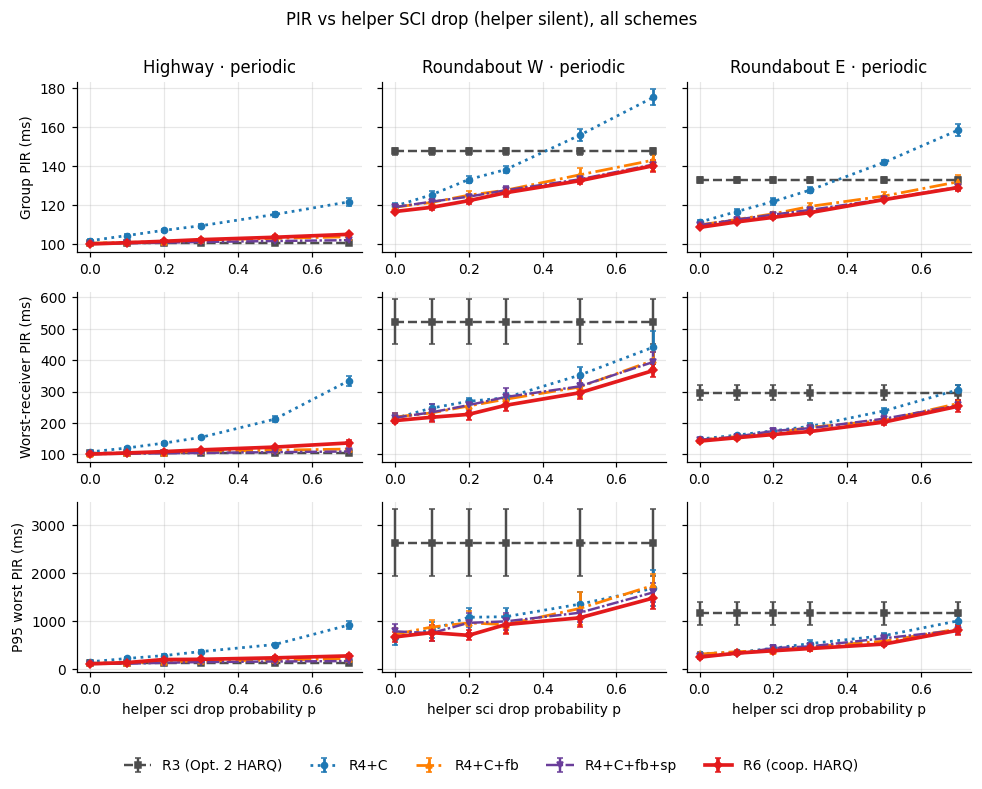

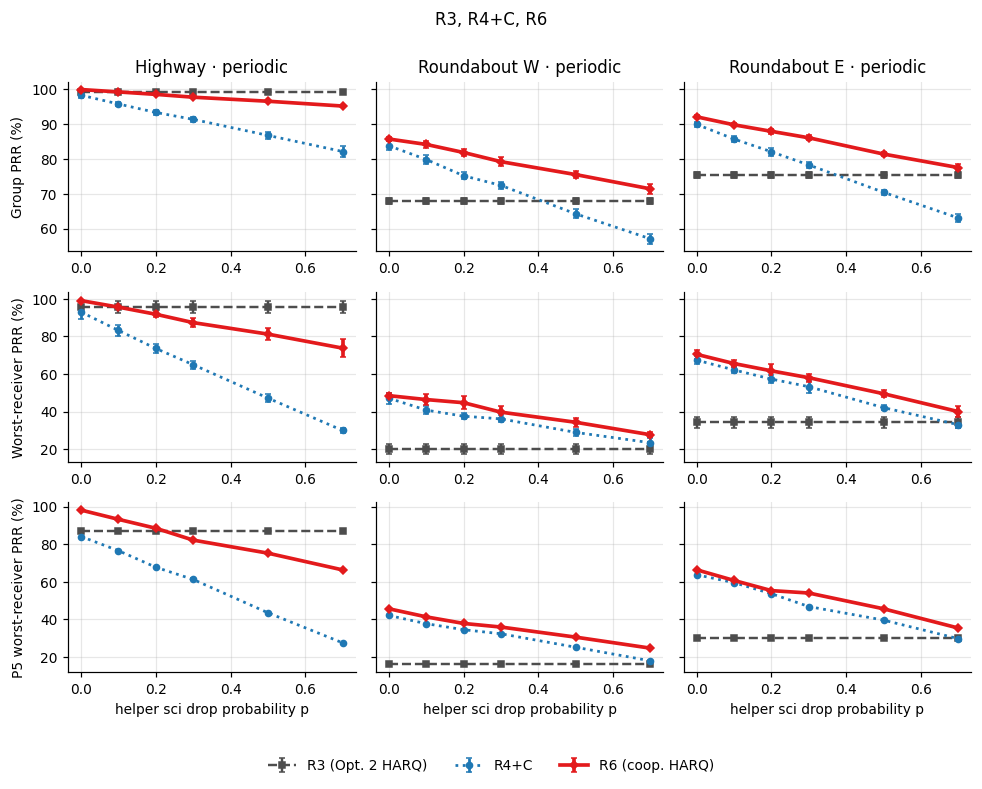

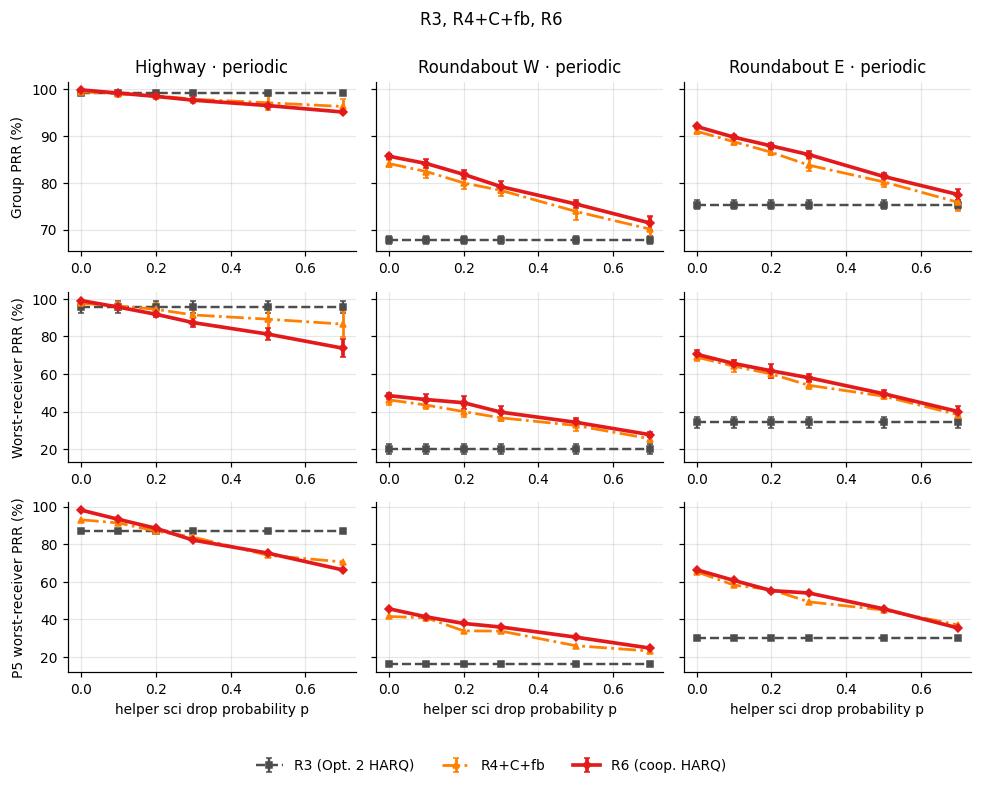

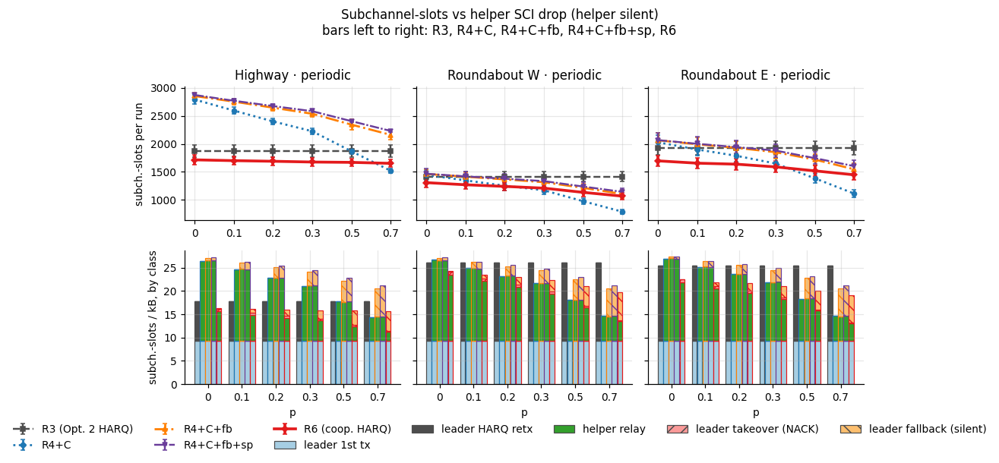

In [15]:
show(P.plot_x(S_HM['sci'], 'hm_p', PRR, ALL, 'helper sci drop probability p', 'Reliability vs helper SCI drop (helper silent), all schemes'), 'hm_sci_prr_all')
show(P.plot_x(S_HM['sci'], 'hm_p', PIR, ALL, 'helper sci drop probability p', 'PIR vs helper SCI drop (helper silent), all schemes', pct=False), 'hm_sci_pir_all')
show(P.plot_x(S_HM['sci'], 'hm_p', PRR, SET_A, 'helper sci drop probability p', 'R3, R4+C, R6'), 'hm_sci_prr_A')
show(P.plot_x(S_HM['sci'], 'hm_p', PRR, SET_B, 'helper sci drop probability p', 'R3, R4+C+fb, R6'), 'hm_sci_prr_B')
show(P.plot_resources(S_HM['sci'], 'hm_p', ALL, 'p', 'Subchannel-slots vs helper SCI drop (helper silent)', xcat=True), 'hm_sci_res')

### 7.2 Helper payload drop (helper NACKs)

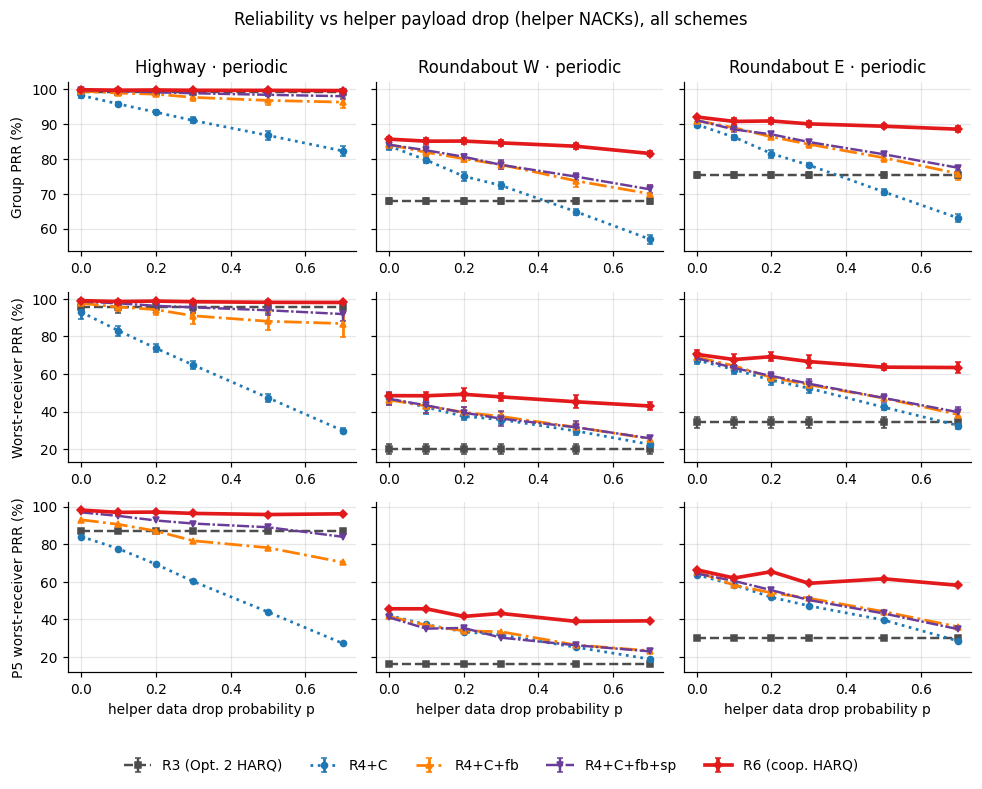

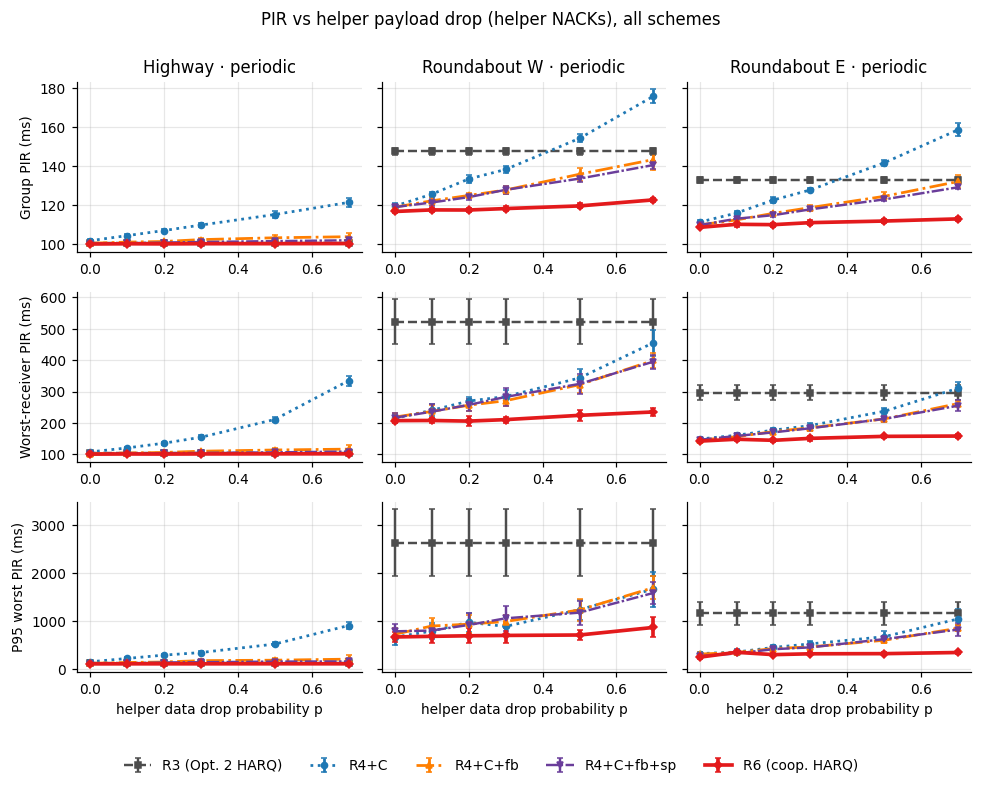

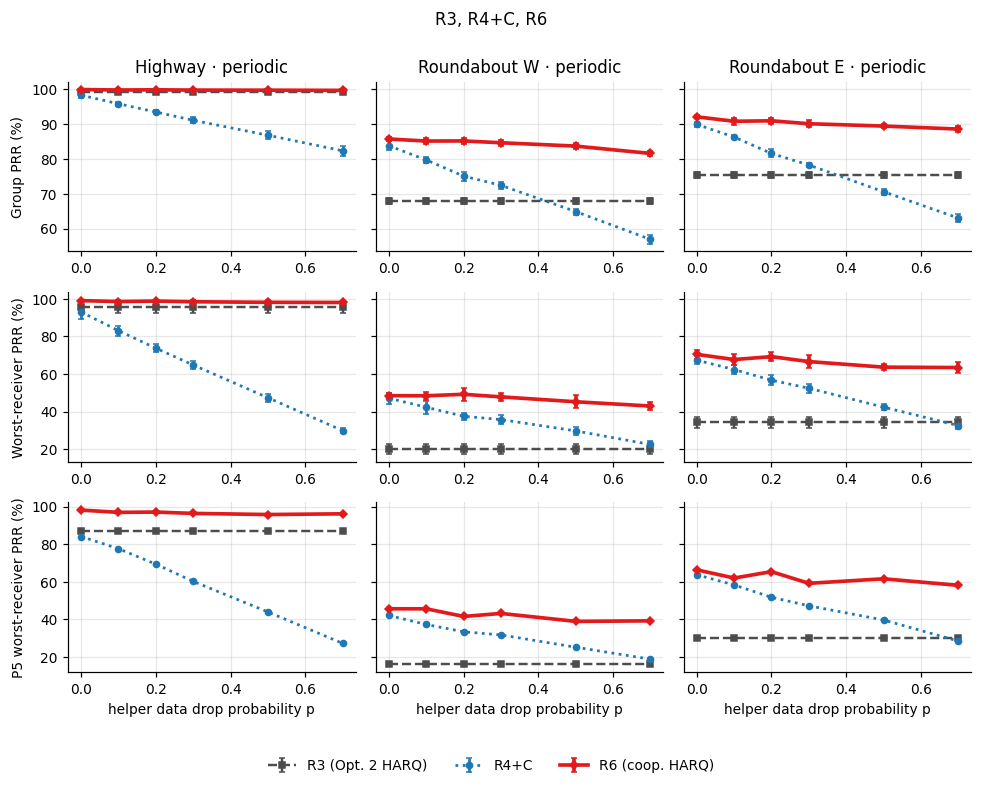

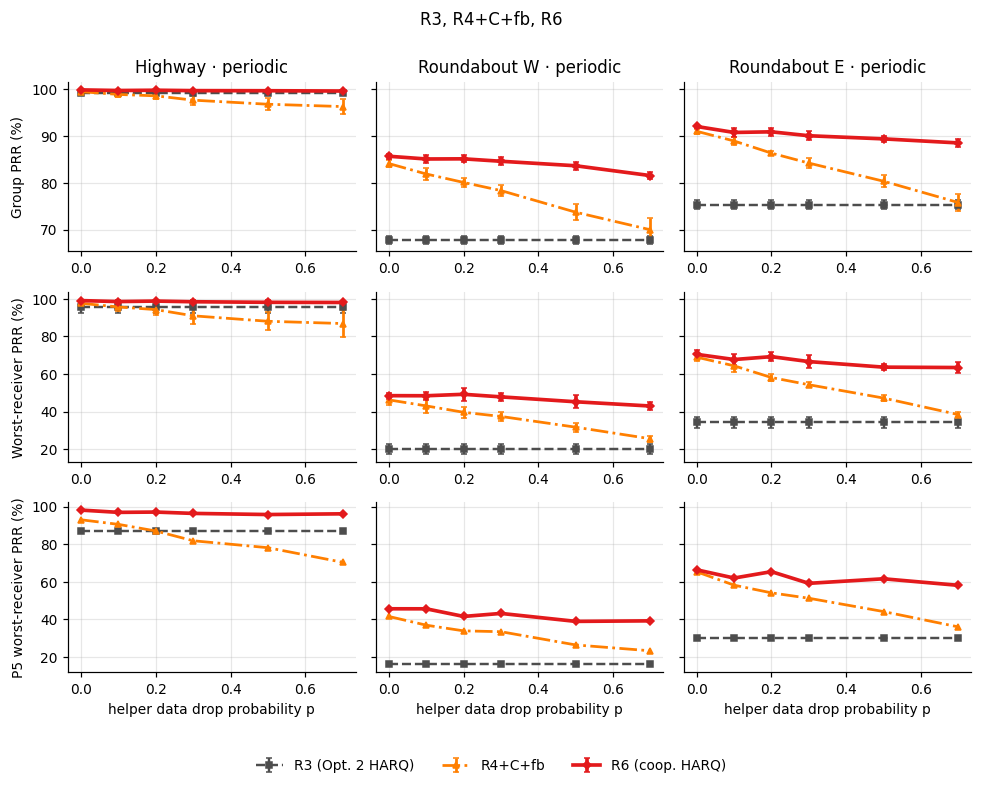

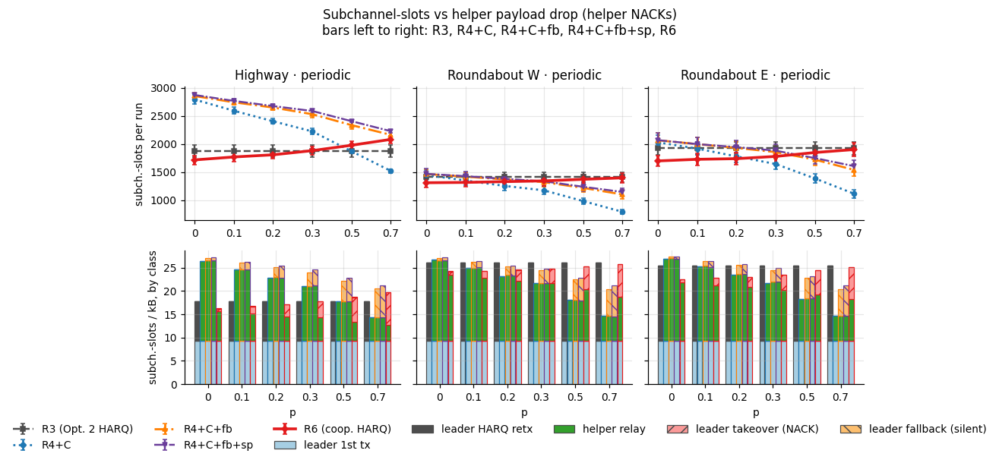

In [16]:
show(P.plot_x(S_HM['data'], 'hm_p', PRR, ALL, 'helper data drop probability p', 'Reliability vs helper payload drop (helper NACKs), all schemes'), 'hm_data_prr_all')
show(P.plot_x(S_HM['data'], 'hm_p', PIR, ALL, 'helper data drop probability p', 'PIR vs helper payload drop (helper NACKs), all schemes', pct=False), 'hm_data_pir_all')
show(P.plot_x(S_HM['data'], 'hm_p', PRR, SET_A, 'helper data drop probability p', 'R3, R4+C, R6'), 'hm_data_prr_A')
show(P.plot_x(S_HM['data'], 'hm_p', PRR, SET_B, 'helper data drop probability p', 'R3, R4+C+fb, R6'), 'hm_data_prr_B')
show(P.plot_resources(S_HM['data'], 'hm_p', ALL, 'p', 'Subchannel-slots vs helper payload drop (helper NACKs)', xcat=True), 'hm_data_res')

## 8. Reliability vs feedback (PSFCH) issues
| issue | model | values | arms |
|---|---|---|---|
| PSFCH miss (DTX) | each received ACK/NACK lost, per receiver | 0.01, 0.05, 0.1, 0.2, 0.3 | R6; R3 at 0.1 |
| NACK -> ACK | a received NACK read as ACK | 0.001, 0.01, 0.05 | R6; R3 at 0.01 |
| PSFCH power | SNR-based PSFCH decoding (1 PRB, format 0) at power P | 23, 10, 0 dBm | R6; R3 at 23 dBm |
| PSFCH period | PSFCH every N slots | 2, 4 | R3, R6 |

Error-free / period 1 = load campaign. R4 arms (no feedback) are drawn as horizontal lines at their error-free value.
8.1-8.3 use run-level PRR (untraced runs); 8.4 is traced.

In [17]:
FB_REF = LOAD[LOAD.nbg.isin([0, 60])]
def fb_frame(issue, traced=False):
    x = R[R.fb_issue == issue]
    ref = FB_REF[FB_REF.arm.isin(['R3', 'R6'])]
    if traced:
        xw = W.merge(x[KEYC], on=KEYC)
        rr, rw = setcols(ref, WL.merge(ref[KEYC], on=KEYC), fb_issue=issue, fb_val=1.0 if issue == 'psfch_period' else 0.0)
        return pd.concat([x, rr]), pd.concat([xw, rw])
    rr, _ = setcols(runlevel(ref), None, fb_issue=issue, fb_val=99.0 if issue == 'psfch_power' else 0.0)
    return pd.concat([runlevel(x), rr]), None

def fb_section(issue, xlabel, xcat=False, xt=None, traced=False, ref_label='error-free'):
    r, w = fb_frame(issue, traced)
    p5 = 'runs'
    cls = None if traced else ['L', 'H']
    for nbg in (0, 60):
        s = H.summarize(r[r.nbg == nbg], w, ['arm', 'sc', 'tr', 'fb_val'], p5_from=p5)
        r4 = FB_REF[(FB_REF.nbg == nbg) & ~FB_REF.arm.isin(['R3', 'R6'])]
        ref = H.summarize(r4 if traced else runlevel(r4), WL if traced else None, ['arm', 'sc', 'tr'], p5_from=p5)
        kw = dict(xcat=xcat, xticklabels=xt, ref=ref, ref_label=ref_label)
        show(P.plot_x(s, 'fb_val', PRR, ALL, xlabel, f'Reliability vs {xlabel}, {nbg} background cars, all schemes', **kw),
             f'fb_{issue}_prr_all_n{nbg}')
        if traced:
            show(P.plot_x(s, 'fb_val', PIR, ALL, xlabel, f'PIR vs {xlabel}, {nbg} background cars', pct=False, **kw),
                 f'fb_{issue}_pir_n{nbg}')
        for nm, arms in (('A', SET_A), ('B', SET_B)):
            names = ', '.join(P.STYLE[a]['label'].split(' ')[0] for a in arms)
            show(P.plot_x(s, 'fb_val', PRR, arms, xlabel, f'{nbg} background cars: {names}', **kw), f'fb_{issue}_prr_{nm}_n{nbg}')
        show(P.plot_resources(s, 'fb_val', ['R3', 'R6'], xlabel, f'Subchannel-slots vs {xlabel}, {nbg} background cars',
                              xcat=True, xticklabels=xt, classes=cls), f'fb_{issue}_res_n{nbg}')
    return r, w

### 8.1 PSFCH miss (DTX) probability

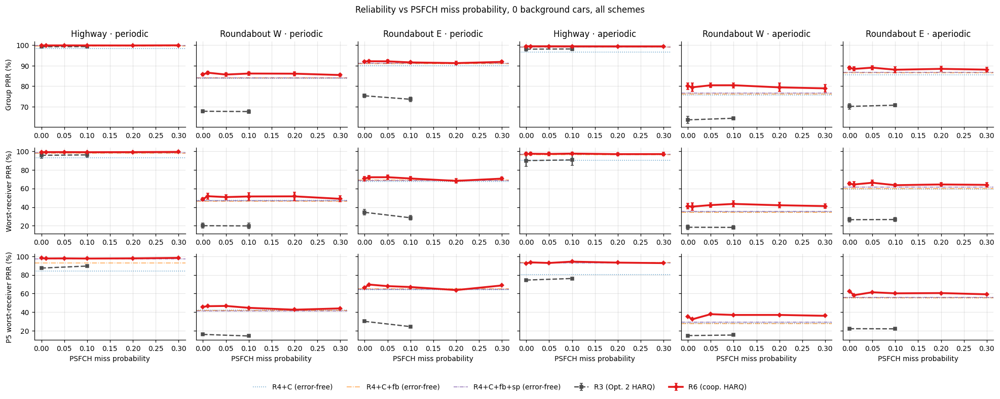

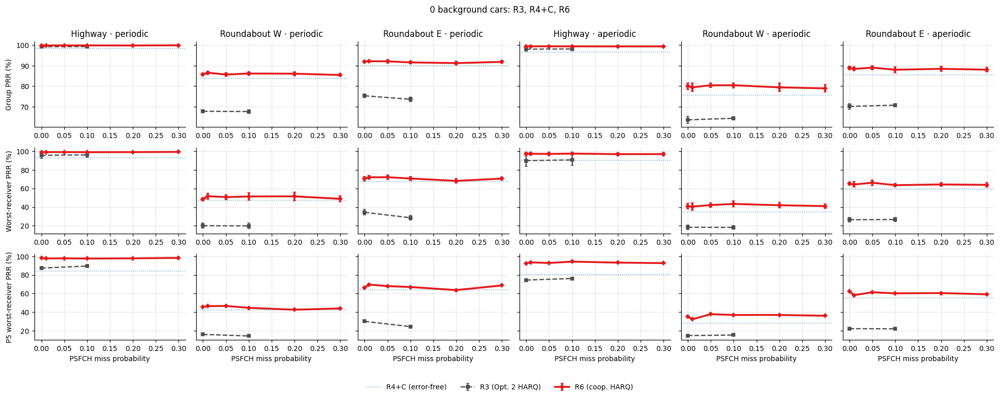

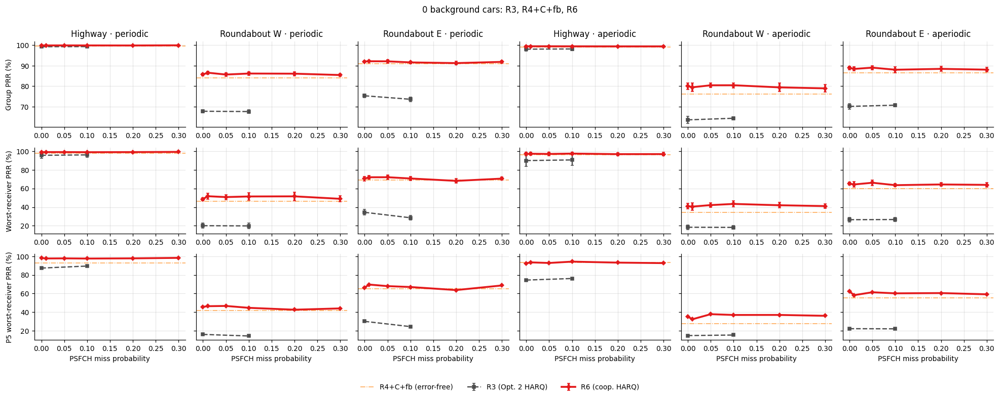

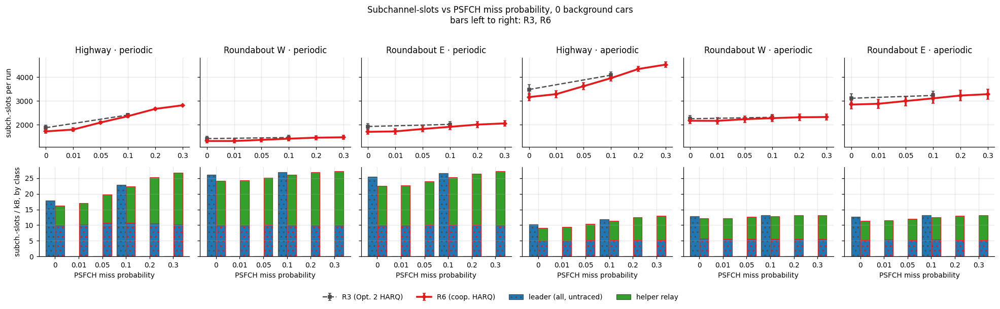

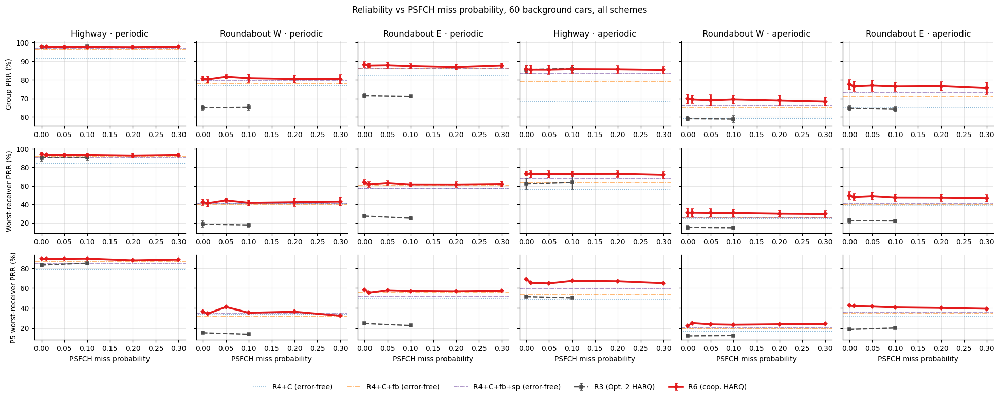

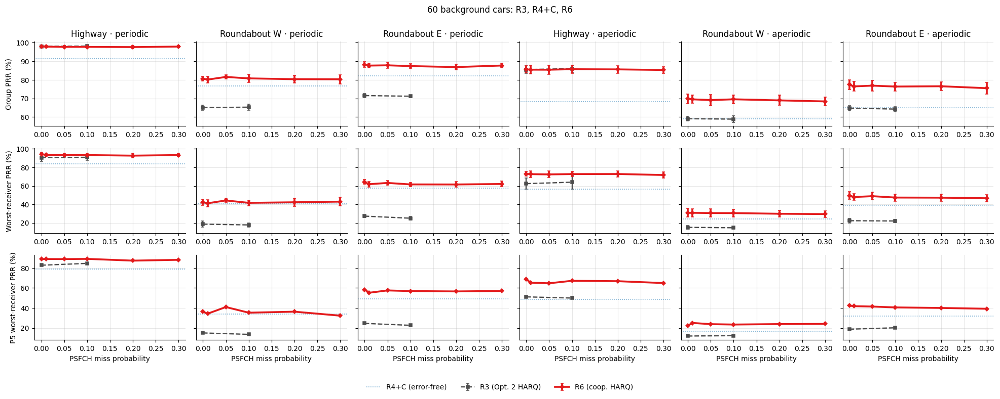

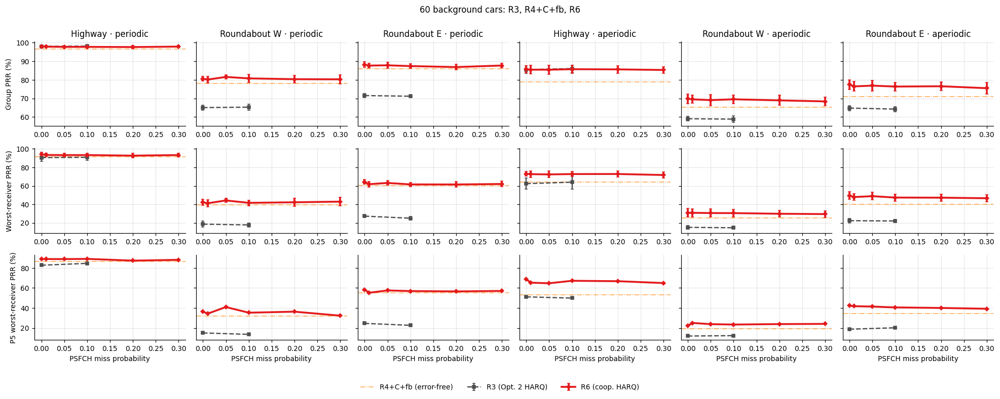

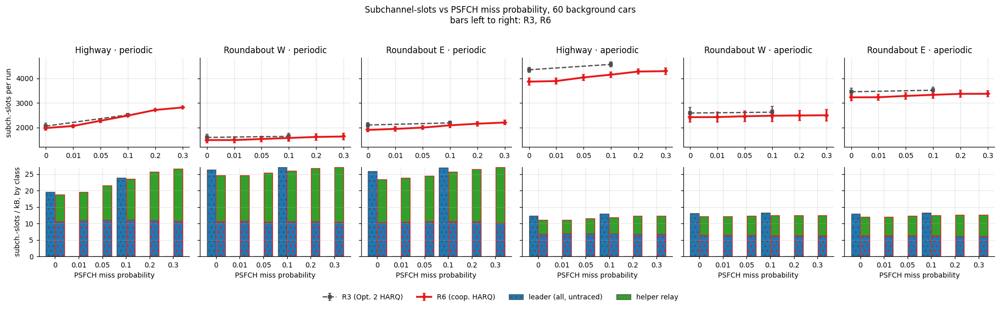

In [18]:
FB = {}; FB['psfch_miss'] = fb_section('psfch_miss', 'PSFCH miss probability')

### 8.2 NACK-to-ACK error probability

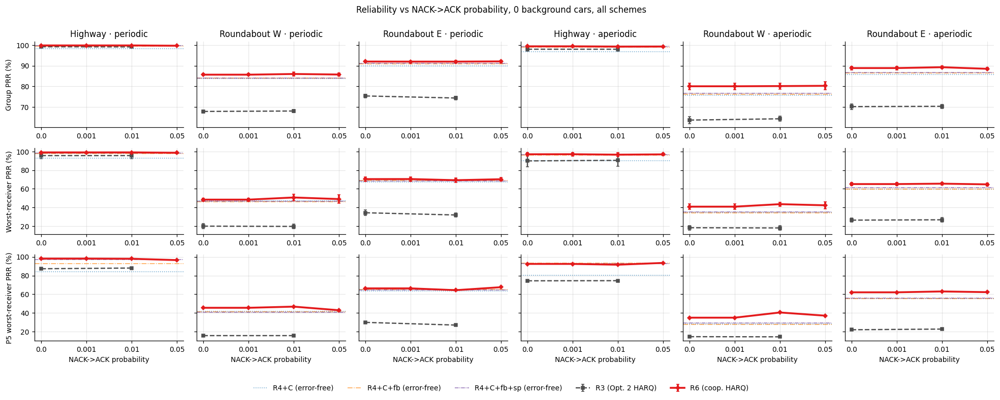

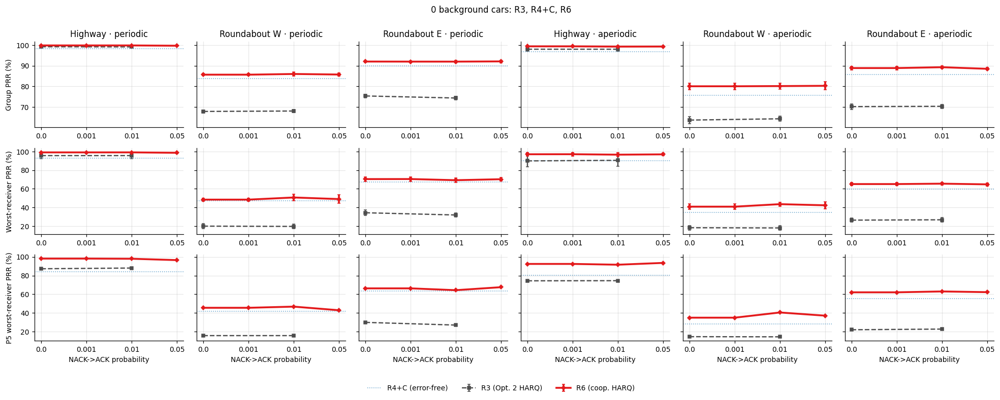

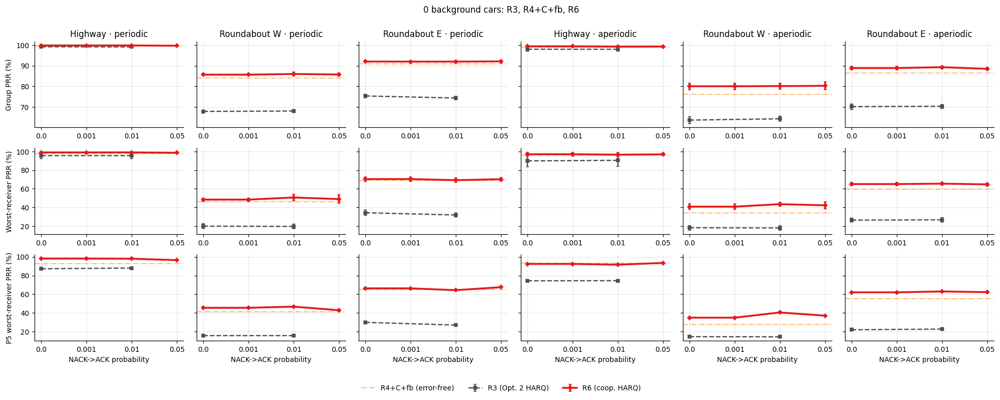

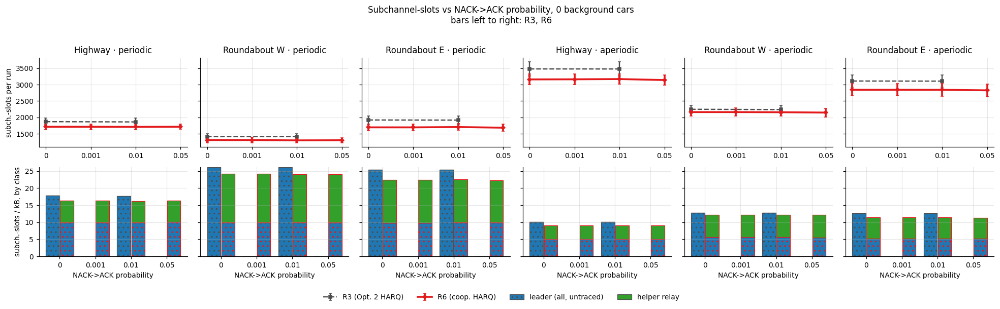

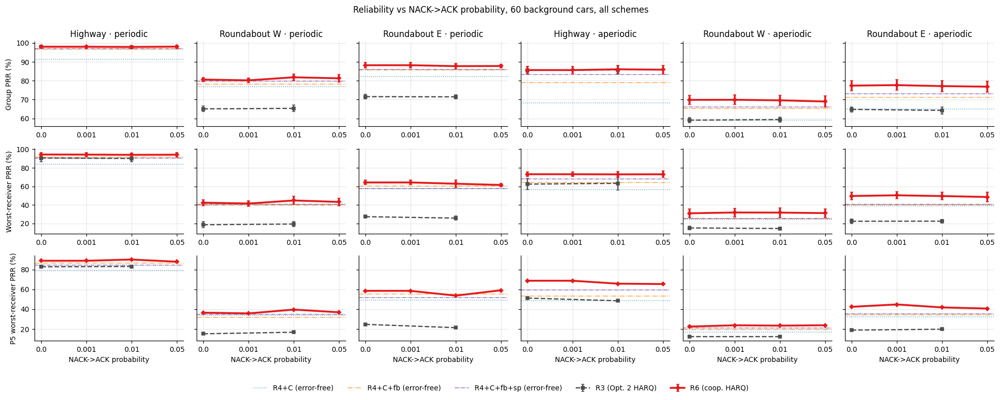

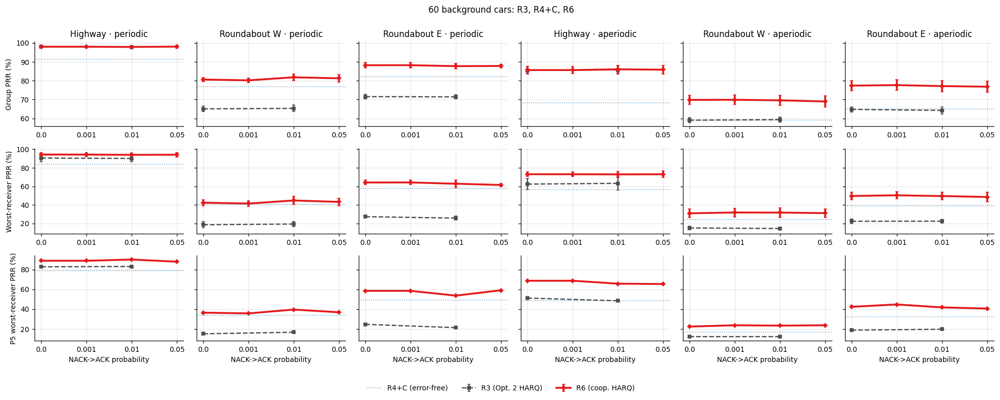

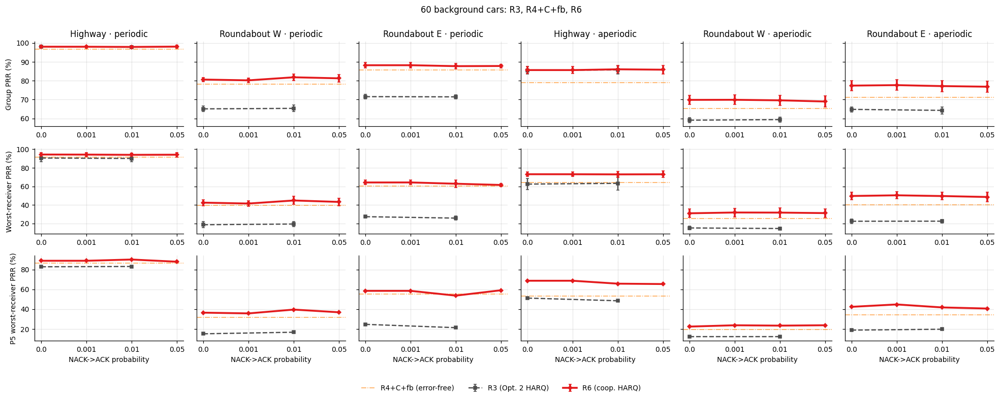

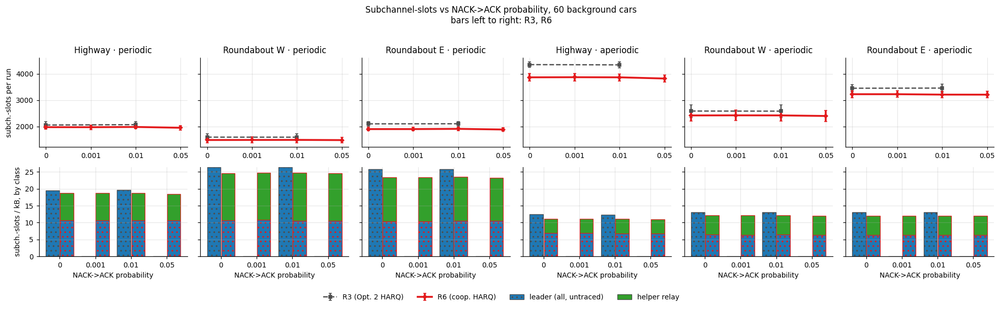

In [19]:
FB['psfch_n2a'] = fb_section('psfch_n2a', 'NACK->ACK probability', xcat=True)

### 8.3 PSFCH transmit power (SNR-based decoding)

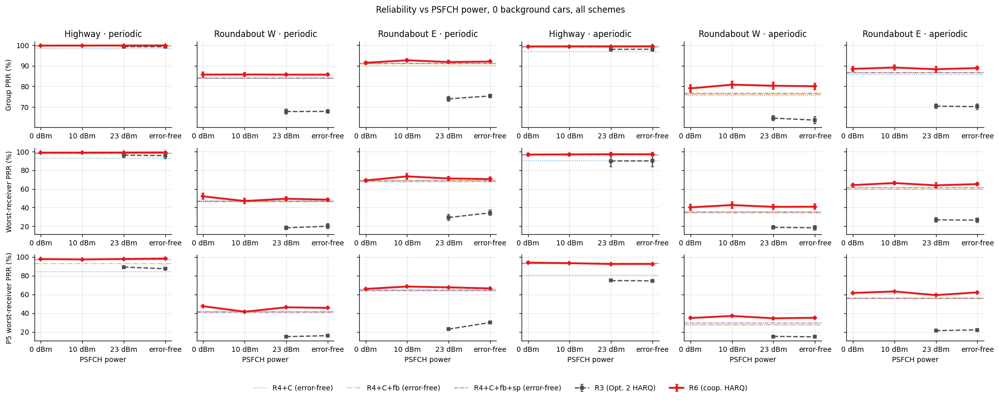

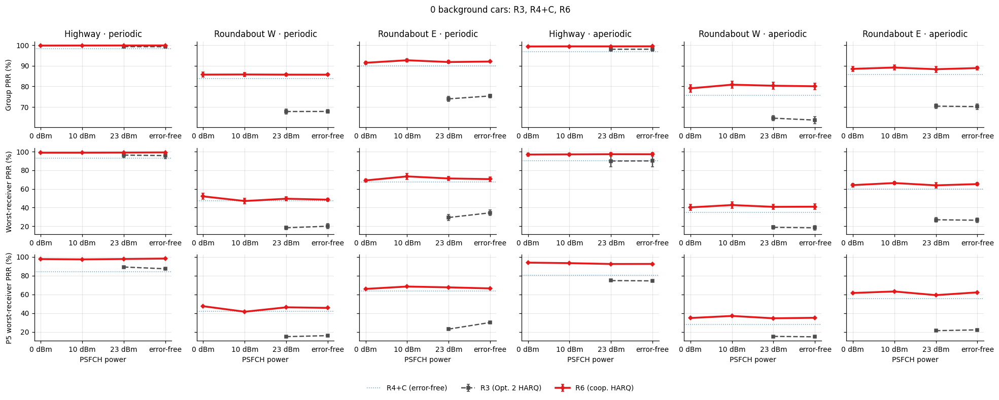

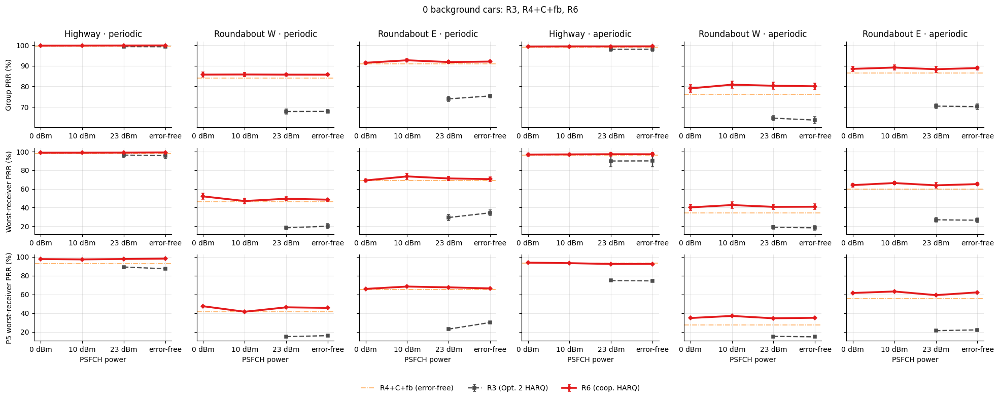

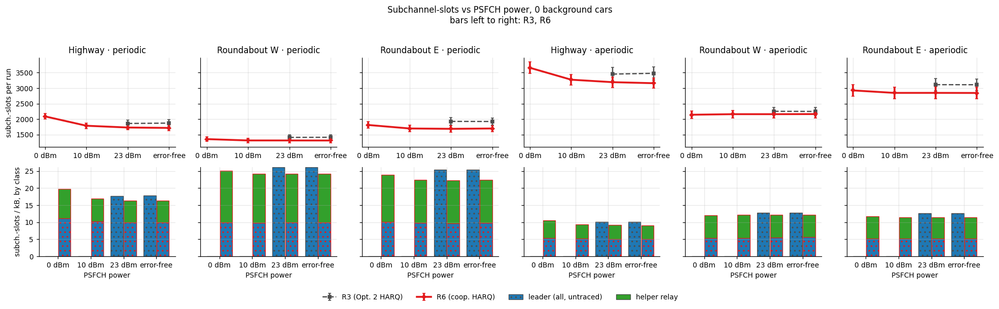

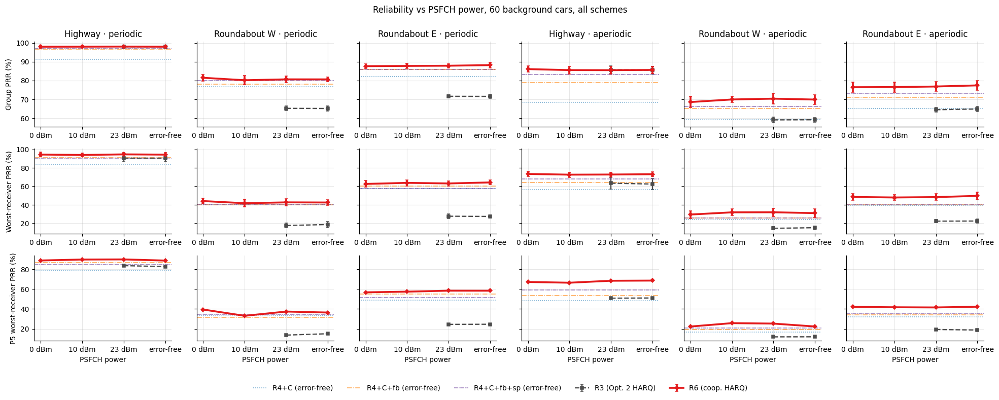

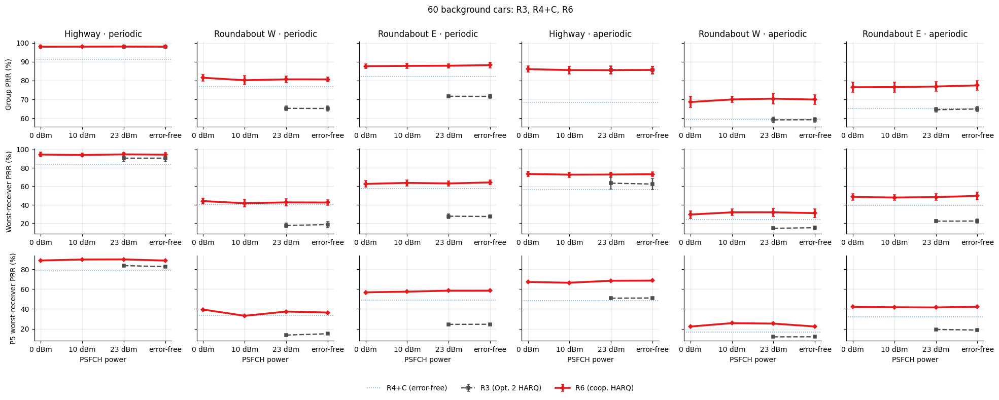

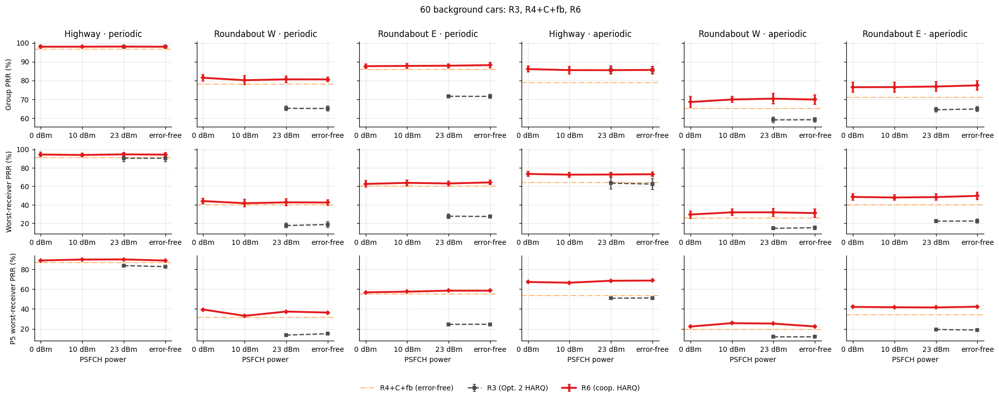

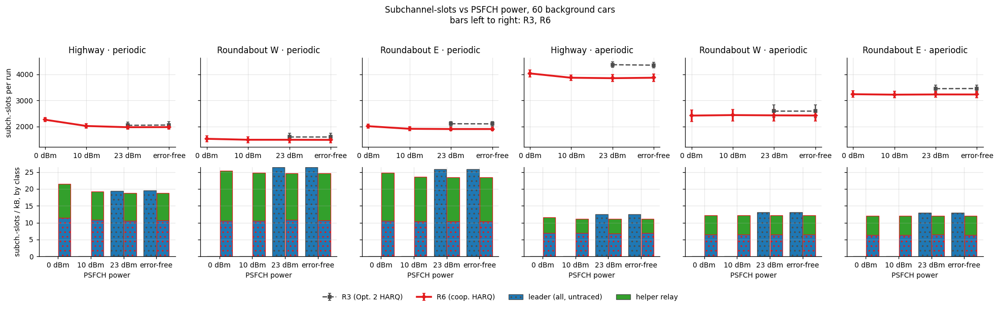

In [20]:
FB['psfch_power'] = fb_section('psfch_power', 'PSFCH power', xcat=True, xt=['0 dBm', '10 dBm', '23 dBm', 'error-free'])

### 8.4 PSFCH period

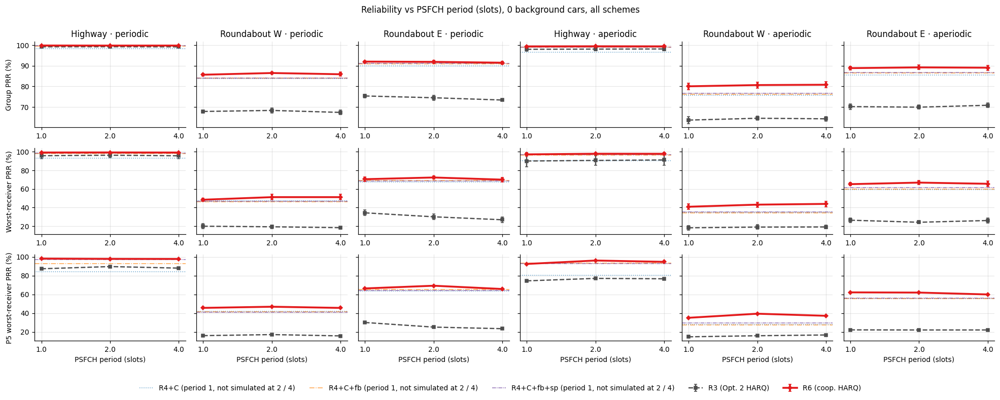

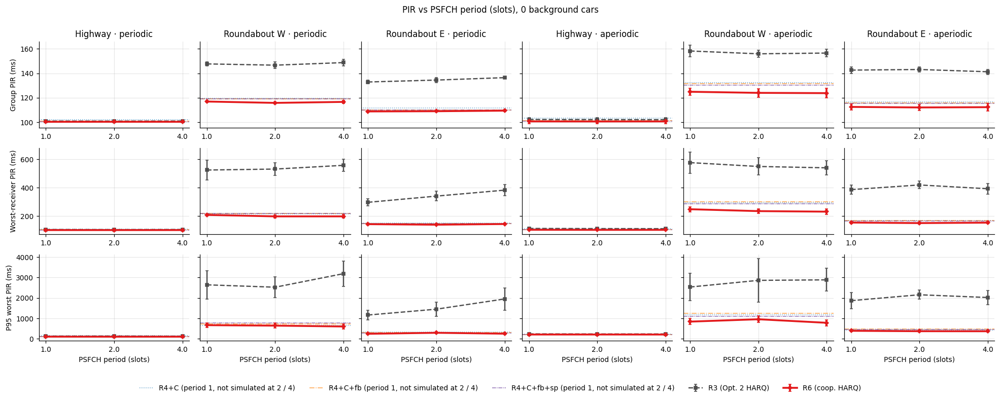

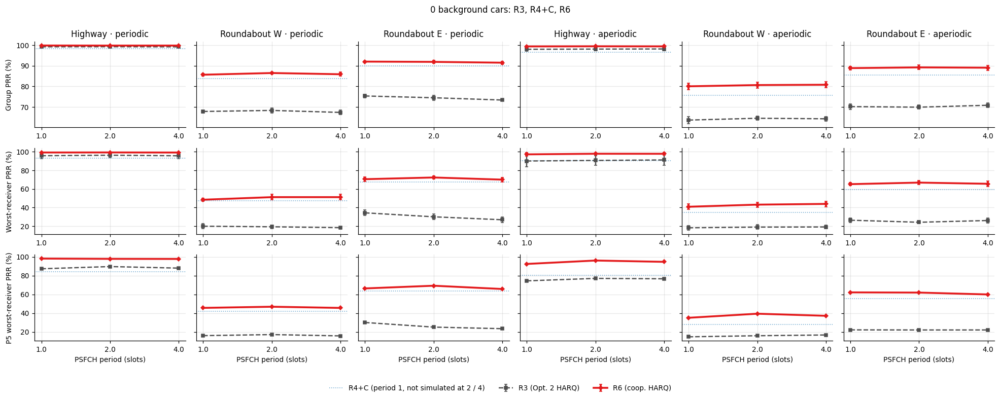

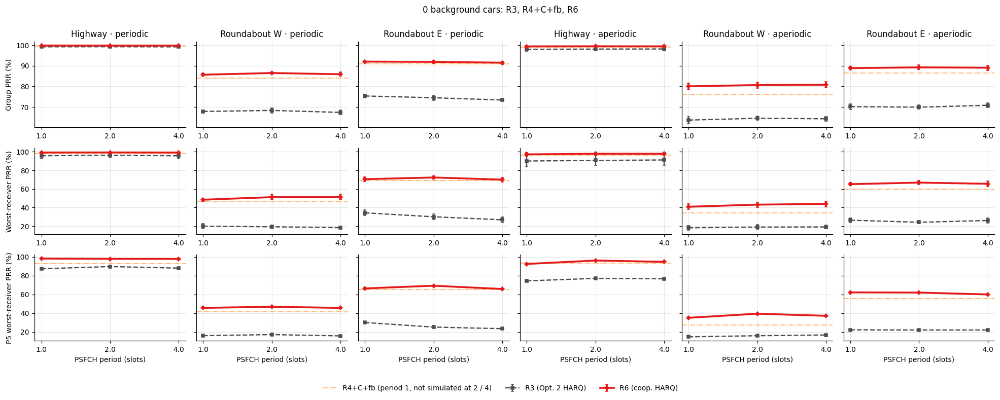

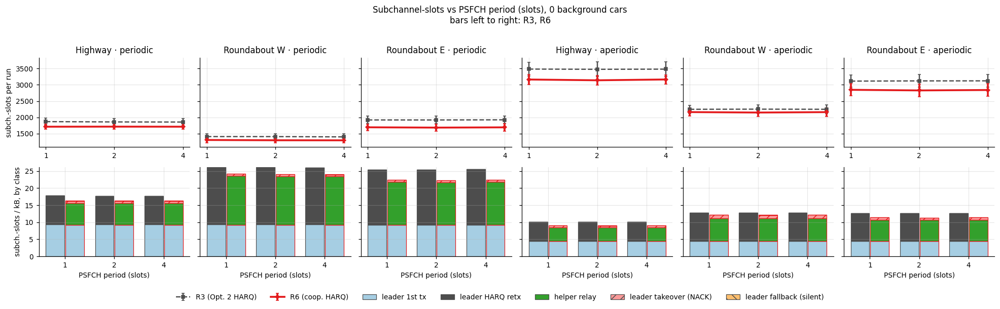

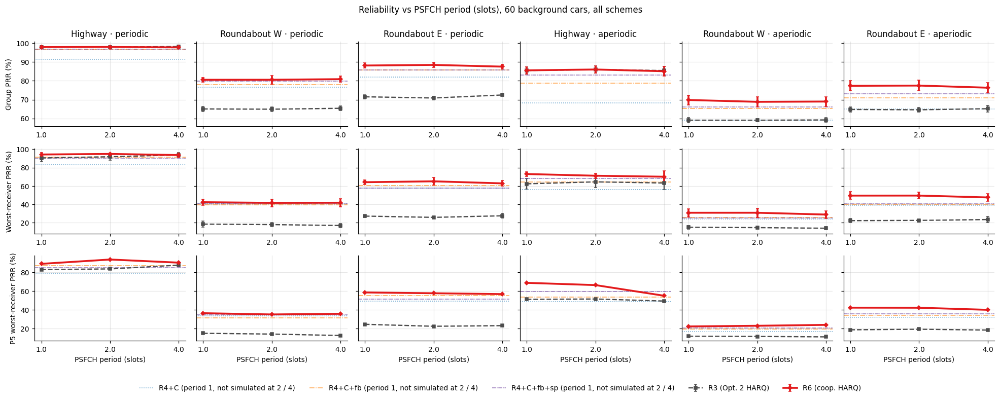

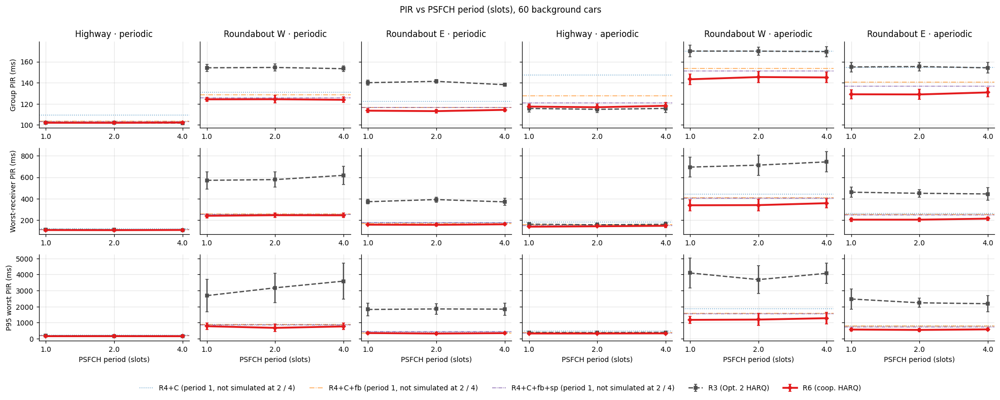

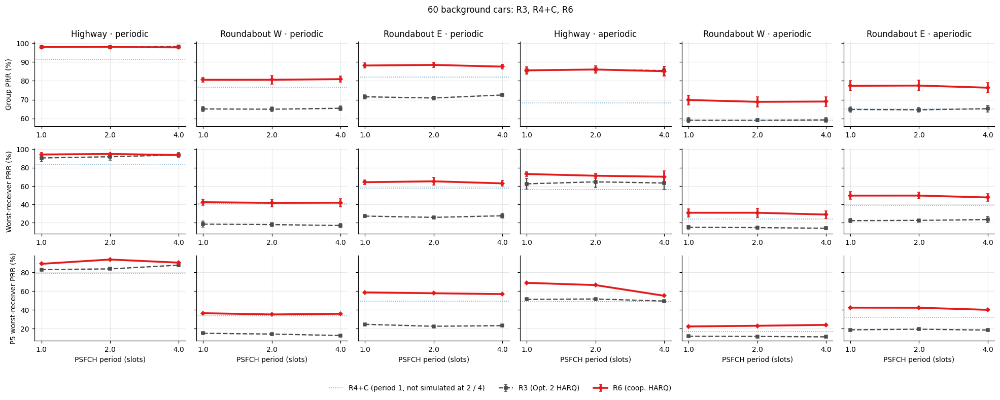

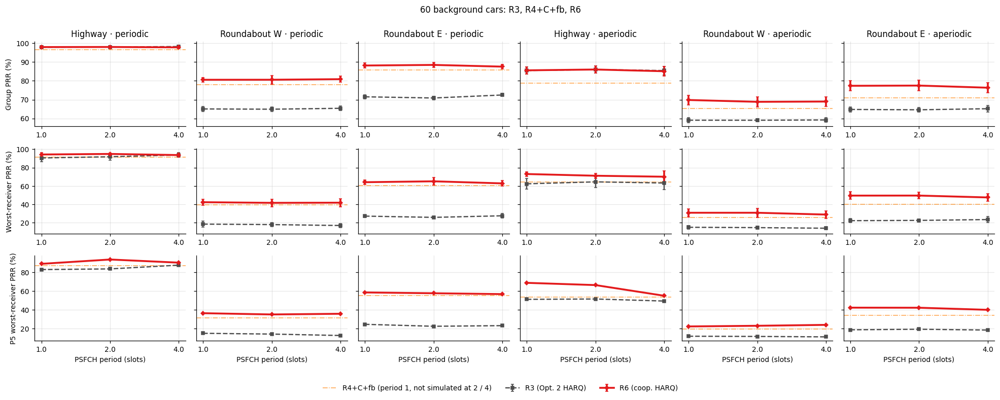

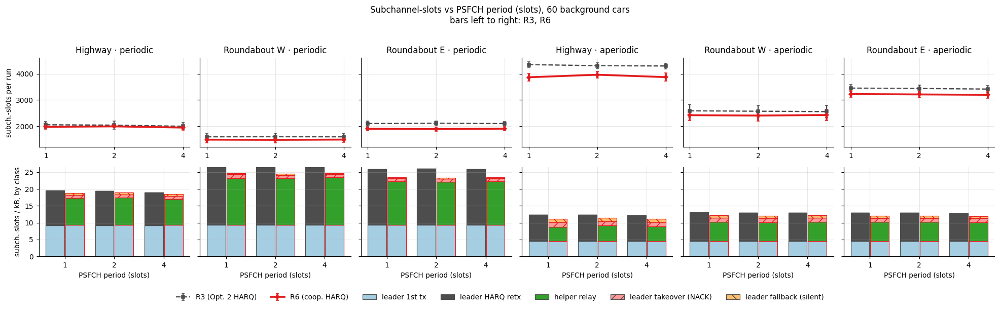

In [21]:
FB['psfch_period'] = fb_section('psfch_period', 'PSFCH period (slots)', xcat=True, traced=True,
                                  ref_label='period 1, not simulated at 2 / 4')

## 9. R6 gain tables
Cell = R6 - X. PRR in percentage points; resources = (R6 - X) / X of subch.-slots per kB generated, in %.
Green = R6 better (higher PRR, fewer resources). One colour scale per metric column. Rows: Highway, then both
roundabouts pooled; traffic; sweep value. Feedback tables: R4+C and R4+C+fb at their error-free value
(no feedback); R3 only where simulated.

In [22]:
OTH = ['R3', 'R4_bsc', 'R4_bsc_fb']
def table(summ, x, title, xlabel, xfmt='{:g}'):
    g = P.gains(summ, x, OTH)
    show(P.gain_heatmap(g, title, xlabel, xfmt=xfmt), 'gain_' + title.split(':')[0].replace(' ', '_'))
    return g

def fb_group(issue):
    r, w = FB[issue]
    traced = w is not None
    r4 = FB_REF[FB_REF.arm.isin(['R4_bsc', 'R4_bsc_fb'])]
    r4 = r4 if traced else runlevel(r4)
    parts, wparts = [r], [w] if traced else []
    for v in sorted(r.fb_val.unique()):
        a, b = setcols(r4, WL.merge(r4[KEYC], on=KEYC) if traced else None, fb_issue=issue, fb_val=v)
        parts.append(a); wparts.append(b) if traced else None
    rr = pd.concat(parts)
    val = rr.fb_val.map(lambda v: 'error-free' if issue == 'psfch_power' and v == 99 else f'{v:g}')
    rr['x'] = rr.nbg.astype(str) + ' cars · ' + val
    ww = None
    if traced:
        ww = pd.concat(wparts)
        ww = ww.merge(rr[KEYC + ['x']].drop_duplicates(KEYC), on=KEYC)
    return H.summarize(rr, ww, ['arm', 'scg', 'tr', 'x'], p5_from='runs')

### 9.1 Background load (pool CBR)

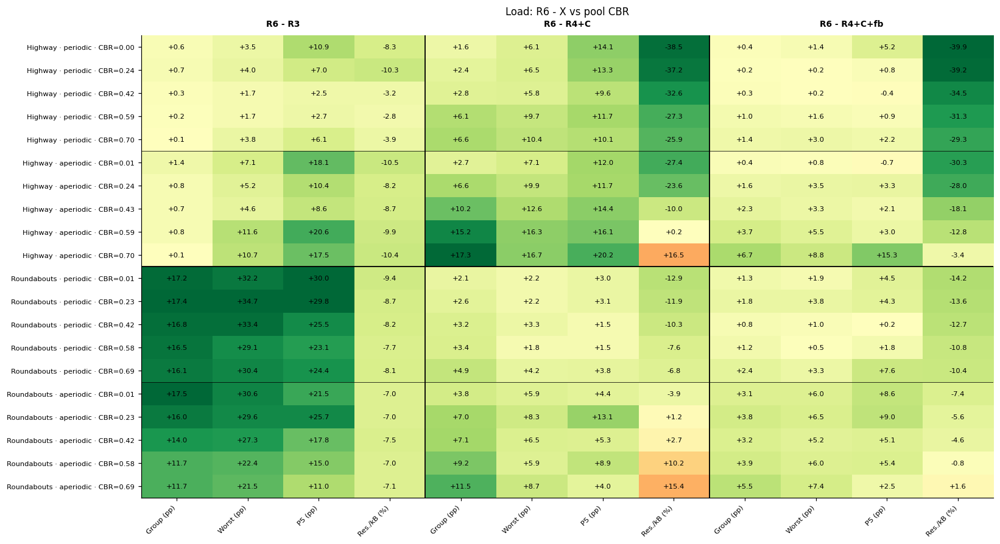

In [23]:
G = {}; G['cbr'] = table(S_LOAD_G, 'cbr_lvl', 'Load: R6 - X vs pool CBR', 'CBR=', '{:.2f}')

### 9.2 Helper SCI drop

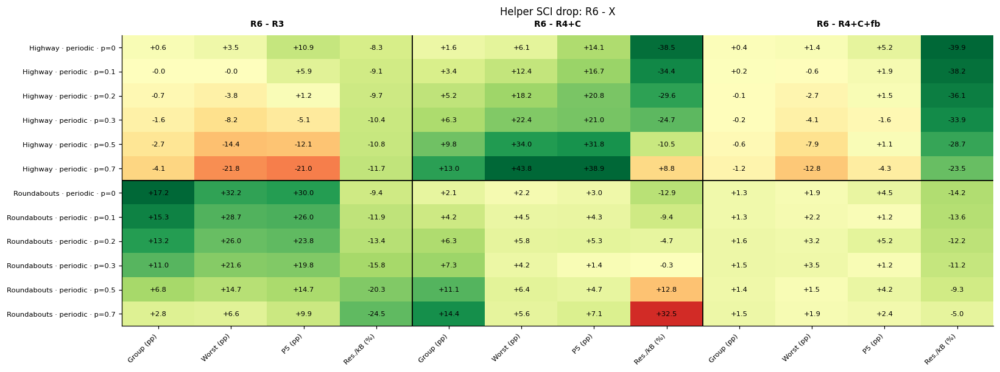

In [24]:
G['hm_sci'] = table(S_HM_G['sci'], 'hm_p', 'Helper SCI drop: R6 - X', 'p=')

### 9.3 Helper payload drop

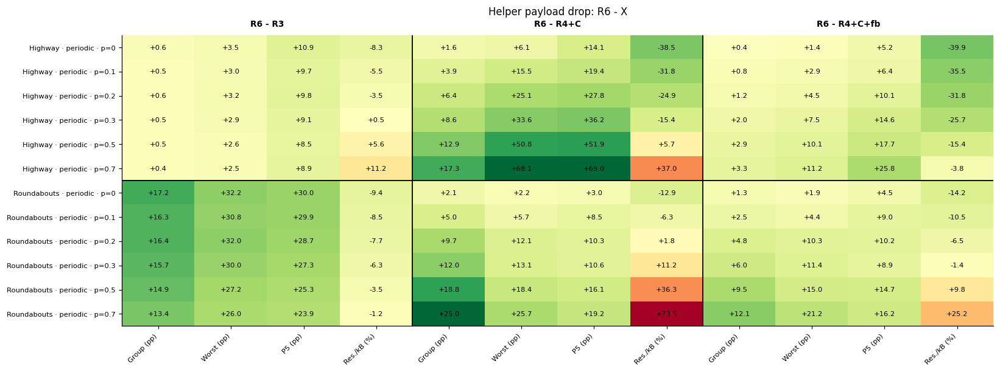

In [25]:
G['hm_data'] = table(S_HM_G['data'], 'hm_p', 'Helper payload drop: R6 - X', 'p=')

### 9.4 PSFCH miss

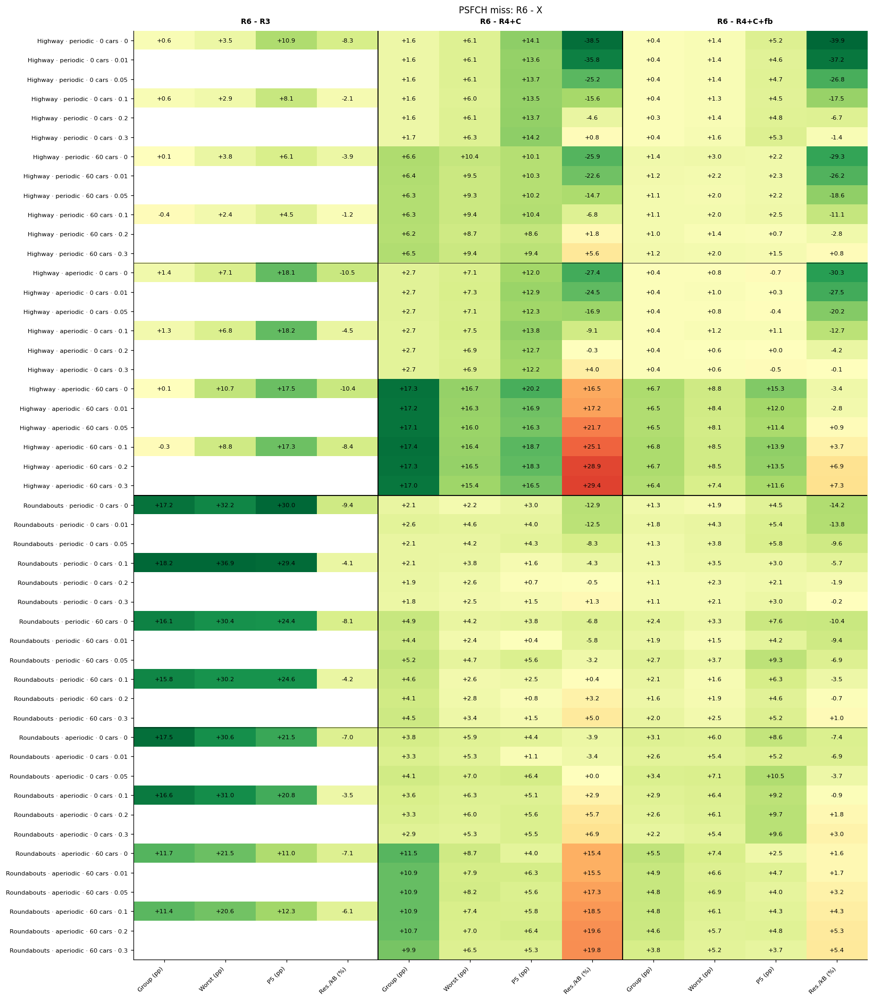

In [26]:
G['psfch_miss'] = table(fb_group('psfch_miss'), 'x', 'PSFCH miss: R6 - X', '', '{}')

### 9.5 NACK->ACK

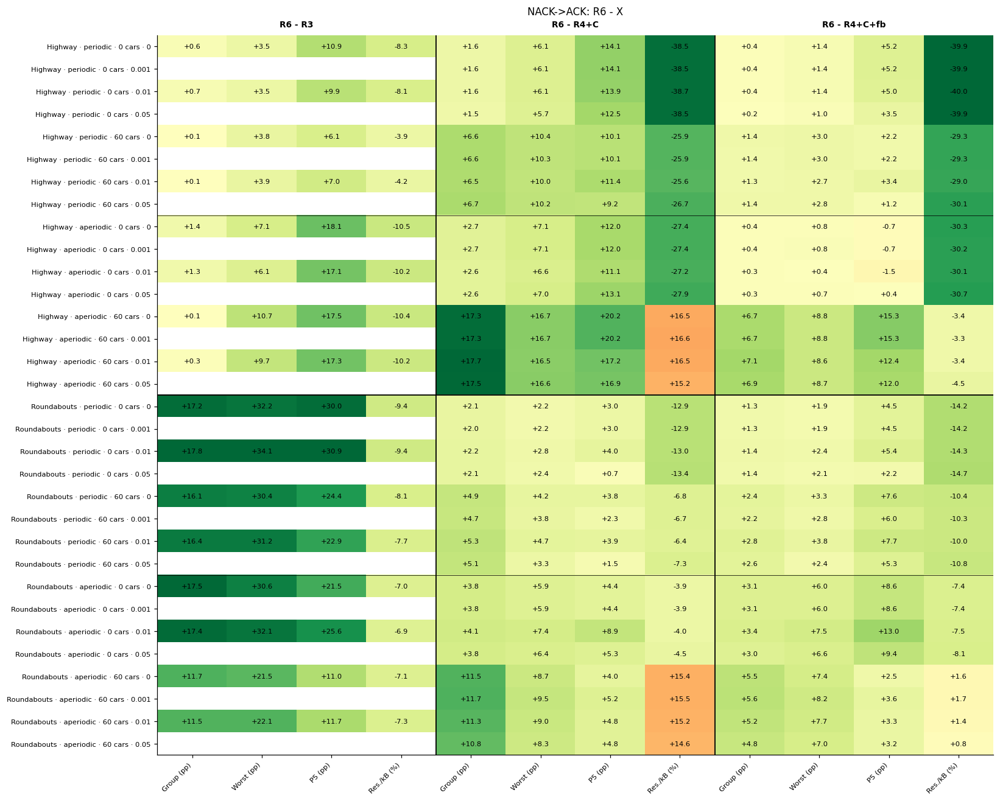

In [27]:
G['psfch_n2a'] = table(fb_group('psfch_n2a'), 'x', 'NACK->ACK: R6 - X', '', '{}')

### 9.6 PSFCH power

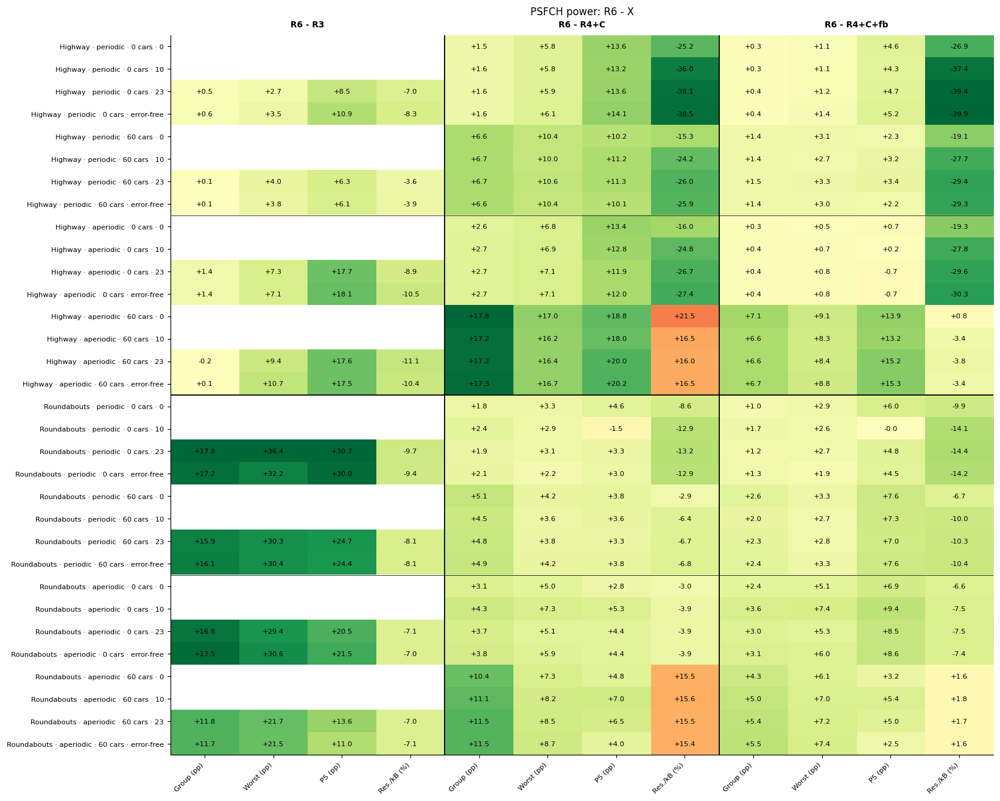

In [28]:
G['psfch_power'] = table(fb_group('psfch_power'), 'x', 'PSFCH power: R6 - X', '', '{}')

### 9.7 PSFCH period

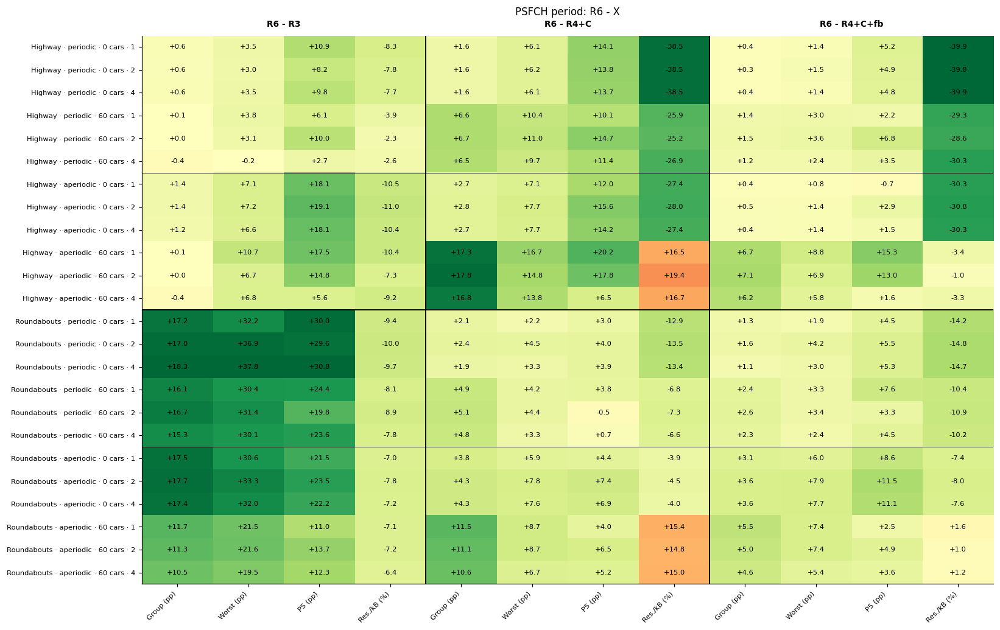

In [29]:
G['psfch_period'] = table(fb_group('psfch_period'), 'x', 'PSFCH period: R6 - X', '', '{}')

### 9.8 All gain tables as data

In [30]:
GT = pd.concat({k: v for k, v in G.items()}, names=['table'])
GT.round(2)

R3 (Opt. 2 HARQ)                                                      R4+C                                                   R4+C+fb  \
                                                   ΔGroup PRR (pp) ΔWorst PRR (pp) ΔP5 PRR (pp) ΔRes./kB (%) ΔGroup PRR (pp) ΔWorst PRR (pp) ΔP5 PRR (pp) ΔRes./kB (%) ΔGroup PRR (pp)   
table        scg         tr                                                                                                                                                              
cbr          Highway     periodic1tb  0.0                     0.64            3.46        10.88        -8.35            1.62            6.10        14.08       -38.55            0.38   
                                      0.24                    0.71            4.04         6.96       -10.33            2.43            6.46        13.29       -37.23            0.17   
                                      0.42                    0.34            1.69         2.49        -3.17            2.84            5.75         9.56       -32.62            0.31   
                                      0.59                    0.22            1.67         2.68        -2.77            6.14            9.72        11.72       -27.31            1.02   
                                      0.7                     0.06            3.76         6.08        -3.90            6.64           10.36        10.12       -25.87            1.40   
...                                                            ...             ...          ...          ...             ...             ...          ...          ...             ...   
psfch_period Roundabouts aperiodic1tb 0 cars · 2             17.69           33.27        23.55        -7.78            4.32            7.81         7.41        -4.52            3.59   
                                      0 cars · 4             17.35           32.01        22.21        -7.24            4.32            7.57         6.95        -4.03            3.59   
                                      60 cars · 1            11.68           21.53        10.96        -7.12           11.53            8.70         4.04        15.40            5.48   
                                      60 cars · 2            11.34           21.60        13.73        -7.16           11.10            8.73         6.46        14.77            5.05   
                                      60 cars · 4            10.49           19.46        12.30        -6.41           10.61            6.72         5.23        14.99            4.55   

                                                                                             
                                                  ΔWorst PRR (pp) ΔP5 PRR (pp) ΔRes./kB (%)  
table        scg         tr                                                                  
cbr          Highway     periodic1tb  0.0                    1.43         5.16       -39.90  
                                      0.24                   0.22         0.75       -39.21  
                                      0.42                   0.22        -0.42       -34.50  
                                      0.59                   1.57         0.93       -31.26  
                                      0.7                    3.04         2.19       -29.26  
...                                                           ...          ...          ...  
psfch_period Roundabouts aperiodic1tb 0 cars · 2             7.95        11.52        -8.05  
                                      0 cars · 4             7.70        11.06        -7.57  
                                      60 cars · 1            7.41         2.46         1.57  
                                      60 cars · 2            7.43         4.88         1.03  
                                      60 cars · 4            5.43         3.65         1.21  

[180 rows x 12 columns]